# Лабораторна робота № 6
## Конвеєр інтелектуального аналізу даних та інтерпретація моделі

**Інтелектуальний аналіз та візуалізація даних** · 4 години · 4 бали

---

### Постановка

Ви — аналітик інтернет-провайдера. Маркетинг просить модель, яка **в момент
звернення клієнта** оцінює ризик, що той розірве договір протягом кварталу.
Модель потрібна не заради числа: за її підказкою відділ утримання
телефонуватиме людям і пропонуватиме знижку. Тому від вас хочуть **дві речі**:

1. чесну оцінку якості;
2. **пояснення**, чому модель вважає конкретного клієнта ризиковим.

Вам видали вивантаження з CRM. Воно зроблене не для аналізу, а для звітності,
тому в ньому є все підряд — зокрема й те, чого в момент прогнозу ще не існує.

> **Попередження, яке варто прочитати двічі.** Перший результат, який ви
> отримаєте, буде прекрасним. Робота полягає в тому, щоб з'ясувати, чому
> йому не можна вірити, і скільки залишиться після того, як ви приберете
> все зайве.

### Що здаєте

Цей ноутбук із заповненими комірками, виконаними **згори вниз без помилок**,
і відповідями на питання розділу 16.

### Як оцінюється

| Частина | Що оцінюється | Балів |
|---|---|---|
| 1 | Конвеєр: обробка, витік, чесне число, вибір методу | 2,0 |
| 2 | Інтерпретація: важливість, PDP, SHAP | 1,5 |
| 3 | Звіт: обґрунтування рішень і виявлені хибні інтерпретації | 0,5 |

Штраф −0,5 бала, якщо ноутбук не виконується згори вниз на чистому ядрі.

---
## 0. Ваш варіант

Впишіть прізвище та номер у списку групи. Файл даних підтягнеться сам.

In [1]:
STUDENT_NAME = 'Голейчук Ілля'     # напр. 'Коваленко Іван Петрович'
LIST_NUMBER  = 2                   # номер у списку групи

assert STUDENT_NAME and LIST_NUMBER > 0, 'впишіть прізвище та номер у списку'
VARIANT = (LIST_NUMBER - 1) % 30 + 1
DATA = 'lr6_варіант_%02d.csv' % VARIANT
print('варіант %d, файл %s' % (VARIANT, DATA))

варіант 2, файл lr6_варіант_02.csv


> Файли варіантів лежать у теці `дані/` поряд із ноутбуком. Якщо викладач
> призначив вам інший варіант — перепишіть `VARIANT` вручну і зазначте це у звіті.

In [2]:
import importlib.util, subprocess, sys
REQUIRED = ['pandas', 'numpy', 'scikit-learn', 'matplotlib', 'shap']
MODNAME  = {'scikit-learn': 'sklearn'}
missing = [p for p in REQUIRED if importlib.util.find_spec(MODNAME.get(p, p)) is None]
if missing:
    print('встановлюю:', ', '.join(missing), '...')
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
print('усі пакети на місці')

усі пакети на місці


In [3]:
import warnings; warnings.filterwarnings('ignore')
import os, re, json, time, datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import (RepeatedStratifiedKFold, cross_val_score,
                                     train_test_split)
from sklearn.inspection import permutation_importance, partial_dependence
from sklearn.metrics import roc_auc_score, confusion_matrix, classification_report

SEED = 42
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 60)
print('усе імпортовано')

усе імпортовано


---
## 1. Три рішення, які ухвалюють ДО того, як торкнутись даних

Нагадування з лекції 7: кроки 1–3 алгоритму виконуються перш ніж
ви напишете хоч один рядок обробки. Якщо обрати метрику після того, як
побачив результати, ви оберете ту, яка показала більше.

### Завдання 1.1

Заповніть три змінні нижче і **обґрунтуйте кожну** одним реченням у коментарі.

In [4]:
# ----- ВАШІ ВІДПОВІДІ -----

TYPE_OF_TASK = 'класифікація'
# чому: ціль «відтік» має два значення (0/1), треба оцінити ймовірність належності до класу «піде».

METRIC = 'AUC'
# чому саме ця, а не точність: відтоку лише 28 %, тож модель «ніхто не піде» вже має точність 0,72,
# а AUC не залежить від порогу й дисбалансу і прямо вимірює вміння ранжувати клієнтів за ризиком,
# що й потрібно відділу утримання для списку на обдзвін.

CV_SCHEME = 'стратифікована 5-кратна, 4 повтори'
# чому саме така: 1200 рядків - замало для однієї відкладеної вибірки; стратифікація тримає
# 28 % відтоку в кожній згортці, а 4 повтори дають 20 оцінок і дозволяють оцінити розкид
# і порівнювати моделі парно на тих самих поділах.

for nme, val in [('TYPE_OF_TASK', TYPE_OF_TASK), ('METRIC', METRIC), ('CV_SCHEME', CV_SCHEME)]:
    assert val, 'не заповнено: ' + nme
print('рішення зафіксовані')

рішення зафіксовані


> **Підказка до METRIC.** Подивіться на частку відтоку в наступному розділі.
> Якщо вона далека від 50 %, подумайте, яку точність дасть модель
> «ніхто не піде» — і чи варта вона чогось.

---
## 2. Перший погляд на дані

### Завдання 2.1

Прочитайте файл і дайте відповідь на чотири питання: скільки рядків і стовпців,
яка частка відтоку, скільки стовпців має невизначений тип, де найбільше пропусків.

In [5]:
raw = pd.read_csv(os.path.join('дані', DATA), encoding='utf-8-sig')
TARGET = 'відтік'

print('розмір:', raw.shape)
print('частка відтоку: %.3f' % raw[TARGET].mean())
print()
print('типи стовпців:', raw.dtypes.astype(str).value_counts().to_dict())

розмір: (1200, 26)
частка відтоку: 0.280

типи стовпців: {'str': 14, 'float64': 7, 'int64': 5}


In [6]:
# ----- ВАШ КОД: таблиця «стовпець | тип | унікальних | % пропусків | приклад» -----
# Відсортуйте за часткою пропусків спадно і покажіть усі стовпці.
overview = pd.DataFrame({
    'стовпець': raw.columns,
    'тип': raw.dtypes.astype(str).values,
    'унікальних': raw.nunique().values,
    '% пропусків': (raw.isna().mean() * 100).round(1).values,
    'приклад': [raw[c].dropna().iloc[0] if raw[c].notna().any() else None for c in raw.columns],
}).sort_values('% пропусків', ascending=False).reset_index(drop=True)
pd.set_option('display.max_rows', 60)
display(overview)

undefined = overview.loc[~overview['тип'].isin(['int64', 'float64']), 'стовпець'].tolist()
print('рядків %d, стовпців %d' % raw.shape)
print('частка відтоку: %.3f' % raw[TARGET].mean())
print('стовпців невизначеного (текстового) типу: %d -> %s' % (len(undefined), undefined))
print('найбільше пропусків:', overview.iloc[0]['стовпець'], '(%.1f %%)' % overview.iloc[0]['% пропусків'])

,стовпець,тип,унікальних,% пропусків,приклад
0,дата_розірвання,str,278,72.0,2024-04-20
1,код_причини_закриття,str,5,72.0,ЦІН-02
2,середній_час_відповіді_хв,float64,263,35.8,13.8
3,трафік_ГБ,str,953,5.0,96.2
4,щомісячний_платіж,str,1122,4.0,304.94
5,аварій_на_ділянці_за_квартал,float64,6,3.0,3.0
6,стать,str,6,0.0,ж
7,місто,str,6,0.0,Самбір
8,id_клієнта,str,1200,0.0,K20000
9,вік,float64,61,0.0,42.0


рядків 1200, стовпців 26
частка відтоку: 0.280
стовпців невизначеного (текстового) типу: 14 -> ['дата_розірвання', 'код_причини_закриття', 'трафік_ГБ', 'щомісячний_платіж', 'стать', 'місто', 'id_клієнта', 'автоплатіж', 'спосіб_оплати', 'тип_підключення', 'тариф', 'філія', 'код_тарифного_плану', 'дата_підключення']
найбільше пропусків: дата_розірвання (72.0 %)


### Завдання 2.2 — три способи, якими дані вже зіпсовані

У вивантаженні є щонайменше три проблеми, кожна з яких тихо зламає модель.
Знайдіть їх і **назвіть конкретні стовпці**.

1. Числова колонка, у якій частина значень записана **текстом**.
2. Колонка, у якій Excel перетворив число на **дату**.
3. Колонка, пропуски в якій **не випадкові** — їхня наявність сама щось означає
   (механізм MNAR за класифікацією Рубіна, розділ 7.2 конспекту).

In [7]:
# ----- ВАШ КОД: знайдіть і покажіть по кілька прикладів кожної проблеми -----
NUM_RE = r'^-?\d+(?:\.\d+)?$'
DATE_RE = r'^\d{4}-\d{2}-\d{2}( \d{2}:\d{2}:\d{2})?$'

print('1) Текстові колонки, де більшість значень - числа, але не всі:')
for c in raw.columns:
    if pd.api.types.is_numeric_dtype(raw[c]) or c == 'дата_підключення':
        continue
    s = raw[c].dropna().astype(str).str.strip()
    is_num = s.str.match(NUM_RE)
    if is_num.mean() > 0.8:
        bad = s[~is_num]
        print('   %-22s числових %.1f %%, нечислових %d, приклади: %s'
              % (c, 100 * is_num.mean(), len(bad), bad.unique()[:5].tolist()))

print()
print('2) Значення-дати всередині числових колонок (Excel-дата):')
for c in raw.columns:
    if c.startswith('дата_') or pd.api.types.is_numeric_dtype(raw[c]):
        continue
    s = raw[c].dropna().astype(str)
    dates = s[s.str.match(DATE_RE)]
    if 0 < len(dates) < 0.5 * len(s):
        print('   %-22s %d значень-дат, приклади: %s' % (c, len(dates), dates.unique()[:3].tolist()))
print('   (1900-01-01 / 1900-01-02 - це числа 1 і 2, які Excel «впізнав» як дати)')

print()
print('3) Пропуски, що щось означають (MNAR):')
c = 'середній_час_відповіді_хв'
g = raw.groupby(raw[c].isna().map({True: 'пропуск', False: 'заповнено'})).agg(
    клієнтів=(TARGET, 'size'), частка_відтоку=(TARGET, 'mean'),
    звернень_мін=('кількість_звернень_у_підтримку', 'min'),
    звернень_макс=('кількість_звернень_у_підтримку', 'max'))
display(g.round(3))
print('   час відповіді відсутній рівно тоді, коли клієнт жодного разу не звертався в підтримку')

1) Текстові колонки, де більшість значень - числа, але не всі:
   щомісячний_платіж      числових 97.7 %, нечислових 27, приклади: ['210.63 грн', '384.39 грн', '266.78 грн', '289.64 грн', '268.59 грн']
   трафік_ГБ              числових 99.7 %, нечислових 3, приклади: ['1900-01-02 00:00:00', '1900-01-01 00:00:00']

2) Значення-дати всередині числових колонок (Excel-дата):
   трафік_ГБ              3 значень-дат, приклади: ['1900-01-02 00:00:00', '1900-01-01 00:00:00']
   (1900-01-01 / 1900-01-02 - це числа 1 і 2, які Excel «впізнав» як дати)

3) Пропуски, що щось означають (MNAR):


,клієнтів,частка_відтоку,звернень_мін,звернень_макс
середній_час_відповіді_хв,,,,
заповнено,771,0.309,1,6
пропуск,429,0.228,0,0


   час відповіді відсутній рівно тоді, коли клієнт жодного разу не звертався в підтримку


In [8]:
PROBLEM_TEXT_IN_NUMBER = 'щомісячний_платіж'    # назва стовпця
PROBLEM_EXCEL_DATE     = 'трафік_ГБ'            # назва стовпця
PROBLEM_MNAR           = 'середній_час_відповіді_хв'    # назва стовпця
MNAR_MEANING           = ('пропуск означає, що клієнт жодного разу не звертався в підтримку '
                          '(0 звернень), тобто відповіді просто не було - це інформація, а не брак')

for nme, val in [('PROBLEM_TEXT_IN_NUMBER', PROBLEM_TEXT_IN_NUMBER),
                 ('PROBLEM_EXCEL_DATE', PROBLEM_EXCEL_DATE),
                 ('PROBLEM_MNAR', PROBLEM_MNAR), ('MNAR_MEANING', MNAR_MEANING)]:
    assert val, 'не заповнено: ' + nme
assert PROBLEM_TEXT_IN_NUMBER in raw.columns and PROBLEM_EXCEL_DATE in raw.columns
assert PROBLEM_MNAR in raw.columns
print('проблеми названо')

проблеми названо


---
## 3. Будуємо матрицю ознак

Перетворення сирої таблиці на матрицю `X` — це фаза 3 CRISP-DM. Усі рішення
тут приймаються **явно** і записуються, бо потім їх доведеться захищати.

### Завдання 3.1

Допишіть `to_number` і `build_X`.

* `to_number` має витягати число з тексту `'350.5 грн'`, **не** перетворювати
  дату на число і повертати `NaN` там, де числа немає.
* `build_X` для кожного стовпця вирішує: число, категорія чи викинути.
  Дата підключення має стати **числом** (напр. порядковим номером дня) —
  інакше модель її не з'їсть.

In [9]:
def to_number(s):
    """Витягує число з колонки, де перемішані числа, текст і дати."""
    DATE_LIKE = re.compile(r'^\s*(\d{4}-\d{1,2}-\d{1,2}|\d{1,2}[./]\d{1,2}[./]\d{2,4})')
    NUMBER = re.compile(r'-?\d+(?:[.,]\d+)?')

    def one(v):
        # 1) None / NaN            -> np.nan
        if v is None:
            return np.nan
        # 2) datetime / Timestamp  -> np.nan   (це брак, а не дані)
        if isinstance(v, (datetime.datetime, datetime.date, pd.Timestamp, np.datetime64)):
            return np.nan
        if isinstance(v, (float, np.floating)) and np.isnan(v):
            return np.nan
        # 3) число                 -> float
        if isinstance(v, (int, float, np.integer, np.floating)) and not isinstance(v, bool):
            return float(v)
        # 4) текст                 -> перше число в ньому, інакше np.nan
        t = str(v).strip()
        if DATE_LIKE.match(t):
            return np.nan
        m = NUMBER.search(t)
        return float(m.group().replace(',', '.')) if m else np.nan
    return s.map(one)

# самоперевірка
_t = pd.Series([1, '350.5 грн', '2,75', datetime.datetime(1900, 1, 11), None, 'немає'])
_r = to_number(_t)
assert _r[0] == 1.0 and abs(_r[1] - 350.5) < 1e-9 and abs(_r[2] - 2.75) < 1e-9
assert np.isnan(_r[3]), 'дата має стати NaN, а не числом'
assert np.isnan(_r[4]) and np.isnan(_r[5])
assert np.isnan(to_number(pd.Series(['1900-01-02 00:00:00']))[0])
print('to_number працює')

to_number працює


In [10]:
DROP_ALWAYS = ['id_клієнта']   # ідентифікатор: нічого не пояснює, лише запам'ятовується

SYNONYMS = {'жін': 'ж', 'чол': 'ч'}
DATE_ORIGIN = pd.Timestamp('2023-01-01')
MISSING_CAT = 'немає'

def build_X(d, drop):
    """Сира таблиця -> матриця ознак. Категорії лишаємо типом category."""
    X = pd.DataFrame(index=d.index)
    log = []
    for c in d.columns:
        if c in drop or c == TARGET:
            continue
        s = d[c]
        if c.startswith('дата_'):
            X[c] = (pd.to_datetime(s, errors='coerce') - DATE_ORIGIN).dt.days.astype(float)
            how = 'дата -> дні від 2023-01-01'
        elif pd.api.types.is_numeric_dtype(s):
            X[c] = s.astype(float)
            how = 'число'
        else:
            num = to_number(s)
            starts_num = s.dropna().astype(str).str.strip().str.match(r'^-?\d')
            num = num.where(s.astype(str).str.strip().str.match(r'^-?\d'))
            share = (starts_num.sum() and num.notna().sum()) / max(s.notna().sum(), 1)
            if share > 0.8:
                X[c] = num
                how = 'текст -> число (розібрано %.1f %%)' % (100 * share)
            else:
                t = s.astype(str).str.strip().str.lower().replace(SYNONYMS)
                X[c] = t.where(s.notna(), MISSING_CAT).astype('category')
                how = 'категорія (%d рівнів)' % X[c].nunique()
        log.append({'стовпець': c, 'рішення': how,
                    'пропусків': int(X[c].isna().sum()) if str(X[c].dtype) != 'category'
                                 else int((X[c] == MISSING_CAT).sum())})
    return X, pd.DataFrame(log)

X_all, log = build_X(raw, DROP_ALWAYS)
y = raw[TARGET].astype(int)
print('матриця ознак:', X_all.shape)
print('категоріальних:', sum(str(X_all[c].dtype) == 'category' for c in X_all.columns))
display(log)

матриця ознак: (1200, 24)
категоріальних: 9


,стовпець,рішення,пропусків
0,вік,число,0
1,стать,категорія (2 рівнів),0
2,місто,категорія (6 рівнів),0
3,філія,категорія (6 рівнів),0
4,тариф,категорія (4 рівнів),0
5,тип_підключення,категорія (3 рівнів),0
6,спосіб_оплати,категорія (3 рівнів),0
7,автоплатіж,категорія (2 рівнів),0
8,кількість_послуг,число,0
9,місяців_обслуговування,число,0


### Завдання 3.2 — конвеєр

Зберіть `make_pipe(X, clf)`: колонковий перетворювач (числові — медіана плюс
стандартизація; категоріальні — мода плюс одиничне кодування) і модель.

> **Чому саме так.** Відповідь у розділі 10 конспекту: усе, що має `fit`,
> мусить опинитись **усередині** конвеєра, інакше крос-валідація бреше.
> Зверніть увагу на `handle_unknown='ignore'` — без нього модель упаде на
> категорії, якої не було в навчальній згортці.

In [11]:
def make_pipe(X, clf):
    num = [c for c in X.columns if str(X[c].dtype) != 'category']
    cat = [c for c in X.columns if str(X[c].dtype) == 'category']
    prep = ColumnTransformer([
        ('num', Pipeline([('imp', SimpleImputer(strategy='median', add_indicator=True)),
                          ('sc', StandardScaler())]), num),
        ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')),
                          ('oh', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), cat),
    ])
    return Pipeline([('prep', prep), ('clf', clf)])

def logreg():
    return LogisticRegression(max_iter=3000, random_state=SEED)

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=4, random_state=SEED)

# самоперевірка: конвеєр має бути єдиним оцінювачем і переживати крос-валідацію
_p = make_pipe(X_all, logreg())
assert hasattr(_p, 'fit') and hasattr(_p, 'predict')
_s = cross_val_score(_p, X_all, y, cv=RepeatedStratifiedKFold(
    n_splits=5, n_repeats=1, random_state=SEED), scoring='roc_auc')
assert len(_s) == 5
print('конвеєр зібрано, пробний прогін AUC %.3f' % _s.mean())

конвеєр зібрано, пробний прогін AUC 1.000


---
## 4. Перший результат

Запустіть модель на **всьому, що є**, — саме так робить дев'ять аналітиків
із десяти, коли їм дали вивантаження і попросили «подивитись, чи взагалі
щось передбачається».

In [12]:
t0 = time.time()
auc_naive = cross_val_score(make_pipe(X_all, logreg()), X_all, y, cv=cv, scoring='roc_auc')
print('ознак    : %d' % X_all.shape[1])
print('AUC      : %.3f ± %.3f' % (auc_naive.mean(), auc_naive.std()))
print('час      : %.1f c' % (time.time() - t0))

ознак    : 24
AUC      : 1.000 ± 0.000
час      : 0.7 c


### Завдання 4.1

Подивіться на число і на таблицю орієнтирів AUC з розділу 4.4 конспекту.

Запишіть у `FIRST_REACTION` одне речення: що саме це число означає
і яка з двох причин високої AUC, найімовірніше, спрацювала.

In [13]:
FIRST_REACTION = (
    'AUC 1,000 ± 0,000 означає ідеальне ранжування в кожній із 20 згорток, а за таблицею '
    'орієнтирів для реальної задачі відтоку 0,75-0,85 вже добре і >0,95 - підозріло; з двох '
    'причин високої AUC (справді легка задача чи витік) тут майже напевно спрацював витік: у '
    'таблиці є поля, що заповнюються вже після розірвання договору.'
)
assert FIRST_REACTION, 'напишіть, що ви думаєте про це число'
print(FIRST_REACTION)

AUC 1,000 ± 0,000 означає ідеальне ранжування в кожній із 20 згорток, а за таблицею орієнтирів для реальної задачі відтоку 0,75-0,85 вже добре і >0,95 - підозріло; з двох причин високої AUC (справді легка задача чи витік) тут майже напевно спрацював витік: у таблиці є поля, що заповнюються вже після розірвання договору.


---
## 5. Шукаємо витік

Чотири типи витоку (розділ 9.1 конспекту) і засіб проти кожного:

| Тип | Засіб |
|---|---|
| цільовий | чек-ліст: чи існує значення в момент прогнозу |
| препроцесинговий | конвеєр |
| часовий | часова схема перевірки |
| груповий | групова схема перевірки |

Починаємо з цільового.

### Завдання 5.1 — автоматичний детектор

Напишіть `leak_scan`: для кожного стовпця перевірте, чи **сам факт
заповненості** передбачає клас. Поріг `min_group` обов'язковий — без нього
детектор видає хибні спрацювання на колонках, заповнених у двох клієнтів.

In [14]:
def leak_scan(d, y, min_group=20):
    """Для кожного стовпця: наскільки добре його заповненість вгадує клас.

    Повертає таблицю зі стовпцями: ознака, заповнено, частка_відтоку_де_заповнено,
    частка_відтоку_де_пропуск, показник (0.5 = нічого, 1.0 = ідеальний поділ).
    """
    rows = []
    for c in d.columns:
        if c == TARGET:
            continue
        filled = d[c].notna()
        n1, n0 = int(filled.sum()), int((~filled).sum())
        ok = min(n1, n0) >= min_group
        rows.append({
            'ознака': c,
            'заповнено': n1,
            'частка_відтоку_де_заповнено': y[filled].mean() if n1 else np.nan,
            'частка_відтоку_де_пропуск': y[~filled].mean() if n0 else np.nan,
            'показник': roc_auc_score(y, filled.astype(int)) if ok else np.nan,
        })
    return pd.DataFrame(rows).sort_values('показник', ascending=False)

scan = leak_scan(raw, y)
display(scan.head(10))

,ознака,заповнено,частка_відтоку_де_заповнено,частка_відтоку_де_пропуск,показник
22,код_причини_закриття,336,1.000000,0.000000,1.000000
23,дата_розірвання,336,1.000000,0.000000,1.000000
17,середній_час_відповіді_хв,771,0.308690,0.228438,0.545718
14,трафік_ГБ,1140,0.280702,0.266667,0.501653
12,щомісячний_платіж,1152,0.280382,0.270833,0.500909
16,аварій_на_ділянці_за_квартал,1164,0.275773,0.416667,0.489831
0,id_клієнта,1200,0.280000,NaN,NaN
1,вік,1200,0.280000,NaN,NaN
2,стать,1200,0.280000,NaN,NaN
3,місто,1200,0.280000,NaN,NaN


### Завдання 5.2 — цільовий витік

Стовпці з показником близько 1,0 заповнені **лише в одного класу**. Такий
стовпець записаний уже після того, як результат став відомий.

Випишіть їх у `TARGET_LEAK` і **для кожного поясніть одним реченням**, чому
його не існує в момент прогнозу.

In [15]:
TARGET_LEAK = [
    'код_причини_закриття',   # причину закриття вносять, коли клієнт уже розірвав договір
    'дата_розірвання',        # дата розірвання з'являється лише після самого розірвання
]
assert len(TARGET_LEAK) >= 2, 'таких стовпців більше ніж один'
assert all(c in raw.columns for c in TARGET_LEAK)
print('цільовий витік:', TARGET_LEAK)

цільовий витік: ['код_причини_закриття', 'дата_розірвання']


In [16]:
X2, _ = build_X(raw, DROP_ALWAYS + TARGET_LEAK)
auc2 = cross_val_score(make_pipe(X2, logreg()), X2, y, cv=cv, scoring='roc_auc')
print('після вилучення цільового витоку: %d ознак, AUC %.3f ± %.3f'
      % (X2.shape[1], auc2.mean(), auc2.std()))

після вилучення цільового витоку: 22 ознак, AUC 0.966 ± 0.007


### Завдання 5.3 — витік, якого детектор НЕ бачить

Число майже не впало. Отже головне ще попереду.

Детектор знаходить колонки, **формально** пов'язані з ціллю. Він безсилий
проти колонки, яка формально бездоганна, але якої **не існує в момент,
коли ухвалюється рішення** — або яка означає не те, що здається.

Перегляньте решту стовпців **очима** і поставте кожному питання з розділу 9.3:

> **Чи міг я знати це значення в ту мить, коли треба ухвалити рішення?**

Нагадування про момент прогнозу: клієнт щойно зателефонував, договір
**чинний**, рішення про знижку ухвалюється **зараз**.

In [17]:
# ----- ВАШ КОД: перегляньте список стовпців, що лишились -----
print(list(X2.columns))
print()
single = {c: roc_auc_score(y, X2[c].fillna(X2[c].median()))
          for c in X2.columns if str(X2[c].dtype) != 'category'}
single = pd.Series({c: max(a, 1 - a) for c, a in single.items()}).sort_values(ascending=False)
display(single.head(8).round(3).to_frame('AUC однієї ознаки'))
display(raw.groupby('оцінка_ризику_менеджером')[TARGET].agg(['size', 'mean']).round(3)
        .rename(columns={'size': 'клієнтів', 'mean': 'частка відтоку'}))

['вік', 'стать', 'місто', 'філія', 'тариф', 'тип_підключення', 'спосіб_оплати', 'автоплатіж', 'кількість_послуг', 'місяців_обслуговування', 'швидкість_тарифу_Мбіт', 'щомісячний_платіж', 'знижка_відсоток', 'трафік_ГБ', 'кількість_звернень_у_підтримку', 'аварій_на_ділянці_за_квартал', 'середній_час_відповіді_хв', 'трафік_МБ', 'код_тарифного_плану', 'індекс_лояльності_CRM', 'дата_підключення', 'оцінка_ризику_менеджером']



,AUC однієї ознаки
оцінка_ризику_менеджером,0.939
щомісячний_платіж,0.695
трафік_МБ,0.646
швидкість_тарифу_Мбіт,0.646
трафік_ГБ,0.645
вік,0.644
місяців_обслуговування,0.628
кількість_послуг,0.584


,клієнтів,частка відтоку
оцінка_ризику_менеджером,,
1.0,245,0.000
2.0,380,0.026
3.0,287,0.254
4.0,185,0.822
5.0,103,0.981


In [18]:
HUMAN_LEAK = [
    'оцінка_ризику_менеджером',   # менеджер ставить оцінку в CRM вручну, коли вже бачить
                                  # наміри клієнта (дзвінки зі скаргами, запит на розірвання),
                                  # фактично ПІСЛЯ того, як рішення піти вже ухвалене
]
HUMAN_LEAK_WHY = (
    'оцінка менеджера заповнена в усіх 1200 клієнтів (пропусків немає), тож детектор за '
    'фактом заповненості нічого не бачить; витік сидить у самому значенні: при оцінці 1 '
    'відтоку 0 %, при 5 - 98 %, тобто людина вже знала результат, а не прогнозувала його.'
)      # чому детектор із 5.1 його не спіймав

assert len(HUMAN_LEAK) >= 1 and HUMAN_LEAK_WHY
assert all(c in raw.columns for c in HUMAN_LEAK)
X3, _ = build_X(raw, DROP_ALWAYS + TARGET_LEAK + HUMAN_LEAK)
auc3 = cross_val_score(make_pipe(X3, logreg()), X3, y, cv=cv, scoring='roc_auc')
print('після вилучення оцінок людини: %d ознак, AUC %.3f ± %.3f'
      % (X3.shape[1], auc3.mean(), auc3.std()))

після вилучення оцінок людини: 21 ознак, AUC 0.863 ± 0.015


> Якщо тут число впало **суттєво** — ви знайшли головне. Якщо ні —
> перечитайте список стовпців ще раз: щось лишилось.

---
## 6. Артефакт збору даних

Лишилась найтонша перевірка. Якщо дані про два класи **збиралися
по-різному** — у різні періоди, різними людьми, за різними правилами —
модель вивчає спосіб запису, а не предмет. Жодна окрема колонка при цьому
не є витоком; витоком є вся таблиця.

Обчислювана перевірка з розділу 9.3: спробувати передбачити **не ціль,
а джерело**. Якщо за тими самими чесними ознаками добре вгадується філія
або період підключення — класи не порівнянні між собою.

### Завдання 6.1 — частка відтоку за філіями і за періодом

,клієнтів,частка_відтоку
філія,,
Ф-01 Центр,191,0.440
Ф-02 Захід,190,0.468
Ф-03 Схід,209,0.196
Ф-04 Південь,194,0.191
Ф-05 Північ,218,0.197
Ф-06 Приміська,198,0.212


дата_підключення,2023Q1,2023Q2,2023Q3,2023Q4,2024Q1,2024Q2,2024Q3,2024Q4
клієнтів,149.000,144.000,157.000,172.000,136.000,126.000,160.000,156.000
частка_відтоку,0.342,0.278,0.287,0.297,0.257,0.246,0.256,0.269


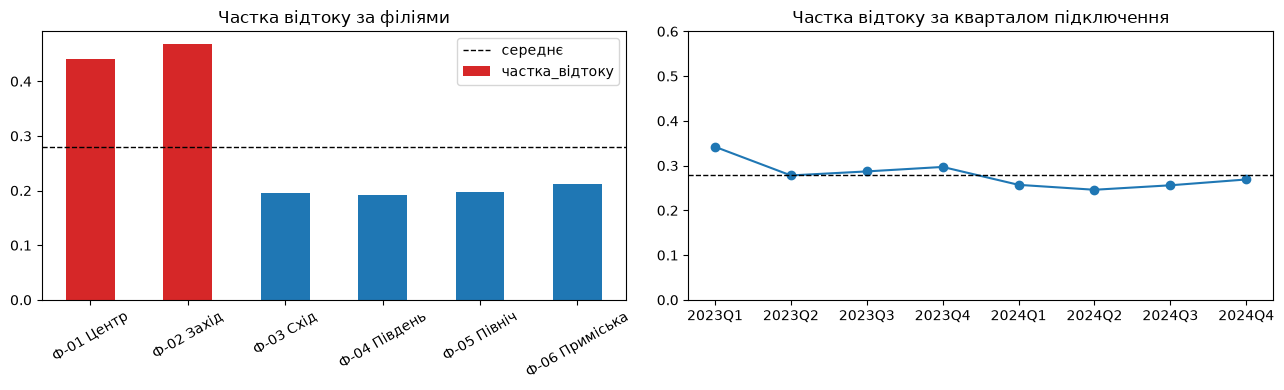

In [19]:
# ----- ВАШ КОД -----
# 1) частка відтоку за кожною філією (і скільки клієнтів у кожній);
by_branch = raw.groupby('філія')[TARGET].agg(клієнтів='size', частка_відтоку='mean').round(3)
display(by_branch)

q = pd.to_datetime(raw['дата_підключення']).dt.to_period('Q').astype(str)
by_q = raw.groupby(q)[TARGET].agg(клієнтів='size', частка_відтоку='mean').round(3)
display(by_q.T)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
by_branch['частка_відтоку'].plot.bar(ax=ax[0], color=['tab:red' if v > 0.35 else 'tab:blue'
                                                       for v in by_branch['частка_відтоку']])
ax[0].axhline(raw[TARGET].mean(), ls='--', c='k', lw=1, label='середнє')
ax[0].set_title('Частка відтоку за філіями'); ax[0].set_xlabel(''); ax[0].legend()
ax[0].tick_params(axis='x', rotation=30)
by_q['частка_відтоку'].plot(ax=ax[1], marker='o')
ax[1].axhline(raw[TARGET].mean(), ls='--', c='k', lw=1)
ax[1].set_ylim(0, 0.6); ax[1].set_title('Частка відтоку за кварталом підключення')
ax[1].set_xlabel('')
plt.tight_layout(); plt.show()
# Шукайте СХОДИНКУ, а не плавну зміну.

### Завдання 6.2 — передбачити джерело

Візьміть **ті самі чесні ознаки**, що й для моделі відтоку, і спробуйте
передбачити ними не `відтік`, а ознаку джерела: «клієнт із філії-підозрюваної»
або «підключений після дати-зламу».

Якщо AUC помітно вища за 0,5 — у ваших даних закодоване джерело.

In [20]:
SUSPECT = 'філія'
assert SUSPECT in ('філія', 'дата_підключення')

# ----- ВАШ КОД: побудуйте бінарну змінну source -----
# для 'філія'          : 1 для філій із різко іншою часткою відтоку
SUSPECT_BRANCHES = by_branch.index[by_branch['частка_відтоку'] > 0.35].tolist()
print('філії-підозрювані:', SUSPECT_BRANCHES)
source = raw['філія'].isin(SUSPECT_BRANCHES).astype(int)
print('частка клієнтів цих філій: %.3f' % source.mean())

X4, _ = build_X(raw, DROP_ALWAYS + TARGET_LEAK + HUMAN_LEAK + [SUSPECT])
auc_src = cross_val_score(make_pipe(X4, logreg()), X4, source, cv=cv, scoring='roc_auc')
auc4 = cross_val_score(make_pipe(X4, logreg()), X4, y, cv=cv, scoring='roc_auc')
print('ті самі ознаки передбачають ДЖЕРЕЛО : AUC %.3f' % auc_src.mean())
print('ті самі ознаки передбачають ВІДТІК  : AUC %.3f ± %.3f' % (auc4.mean(), auc4.std()))

філії-підозрювані: ['Ф-01 Центр', 'Ф-02 Захід']
частка клієнтів цих філій: 0.318
ті самі ознаки передбачають ДЖЕРЕЛО : AUC 0.641
ті самі ознаки передбачають ВІДТІК  : AUC 0.813 ± 0.026


### Завдання 6.3 — драбина

Зведіть усі чотири числа в одну таблицю і подивіться, **де саме** впало.

In [21]:
ladder = pd.DataFrame([
    {'крок': '1. усе підряд',               'ознак': X_all.shape[1], 'AUC': auc_naive.mean()},
    {'крок': '2. мінус цільовий витік',     'ознак': X2.shape[1],    'AUC': auc2.mean()},
    {'крок': '3. мінус оцінки людини',      'ознак': X3.shape[1],    'AUC': auc3.mean()},
    {'крок': '4. мінус артефакт збору',     'ознак': X4.shape[1],    'AUC': auc4.mean()},
]).set_index('крок').round(3)
display(ladder)

HONEST_AUC = float(auc4.mean())
print('чесне число: %.3f ± %.3f' % (HONEST_AUC, auc4.std()))

,ознак,AUC
крок,,
1. усе підряд,24,1.000
2. мінус цільовий витік,22,0.966
3. мінус оцінки людини,21,0.863
4. мінус артефакт збору,20,0.813


чесне число: 0.813 ± 0.026


### Завдання 6.4

Чи **правильно** викидати підозрюваний стовпець? Це не риторичне питання:
філія або дата підключення цілком можуть нести справжній сигнал
(щільна забудова, нові тарифи), а не лише артефакт.

Запишіть своє рішення і аргумент. Обидві відповіді приймаються — оцінюється
аргумент, а не вибір.

In [22]:
DECISION_ARTEFACT = 'викинути'    # 'викинути' / 'залишити' / 'залишити, але звітувати окремо'
DECISION_WHY = (
    'частка відтоку стрибає сходинкою (Ф-01 Центр 0,44 і Ф-02 Захід 0,47 проти 0,19-0,21 в '
    'решті), а не змінюється плавно, а склад клієнтів цих філій відрізняється помірно (AUC '
    'передбачення джерела 0,64): вони трохи молодші (36,6 проти 40,7 року) і частіше на '
    'оптиці, але це не пояснює подвоєння відтоку; найімовірніше, у двох філіях інакше '
    'фіксують розірвання. Модель, що спирається на код філії, не перенесеться в нову філію, '
    'тому для чесного числа філію викидаю (ціна - 0,05 AUC: 0,863 -> 0,813), а різницю між '
    'філіями звітую окремо.'
)
assert DECISION_ARTEFACT and DECISION_WHY
print(DECISION_ARTEFACT, '—', DECISION_WHY)

викинути — частка відтоку стрибає сходинкою (Ф-01 Центр 0,44 і Ф-02 Захід 0,47 проти 0,19-0,21 в решті), а не змінюється плавно, а склад клієнтів цих філій відрізняється помірно (AUC передбачення джерела 0,64): вони трохи молодші (36,6 проти 40,7 року) і частіше на оптиці, але це не пояснює подвоєння відтоку; найімовірніше, у двох філіях інакше фіксують розірвання. Модель, що спирається на код філії, не перенесеться в нову філію, тому для чесного числа філію викидаю (ціна - 0,05 AUC: 0,863 -> 0,813), а різницю між філіями звітую окремо.


---
## 7. Крок 4 алгоритму: який метод узяти

Тепер, коли набір ознак чесний, можна обирати модель. Критеріїв чотири
(розділ 6 конспекту), і всі чотири вимірюються.

### Завдання 7.1

Порівняйте щонайменше чотири моделі **на тому самому наборі й тій самій
схемі перевірки**. Для кожної запишіть AUC, розкид і час на 100 навчань.

In [23]:
from sklearn.tree import DecisionTreeClassifier

MODELS = {
    'логістична регресія':  logreg(),
    'одне дерево':          DecisionTreeClassifier(max_depth=5, min_samples_leaf=20,
                                                   random_state=SEED),
    'випадковий ліс':       RandomForestClassifier(n_estimators=300, min_samples_leaf=3,
                                                   random_state=SEED, n_jobs=-1),
    'гістограмний бустинг': HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05,
                                                           random_state=SEED),
}

rows = []
for name, clf in MODELS.items():
    assert clf is not None, 'заповніть модель: ' + name
    t0 = time.time()
    a = cross_val_score(make_pipe(X4, clf), X4, y, cv=cv, scoring='roc_auc')
    rows.append({'модель': name, 'AUC': round(a.mean(), 3), '±': round(a.std(), 3),
                 'с на 100 навчань': round((time.time() - t0) * 100 / cv.get_n_splits(), 1)})
cmp_models = pd.DataFrame(rows).set_index('модель')
display(cmp_models)

c:\Users\GIGABYTE\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\GIGABYTE\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\GIGABYTE\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c

,AUC,±,с на 100 навчань
модель,,,
логістична регресія,0.813,0.026,3.6
одне дерево,0.762,0.027,3.1
випадковий ліс,0.834,0.029,39.7
гістограмний бустинг,0.830,0.024,50.5


### Завдання 7.2 — парне порівняння

Різниця середніх ще нічого не доводить: розкид між згортками може бути
більшим за саму різницю. Порівняйте **поскладово** (розділ 11.4 конспекту):
обидві моделі на тих самих поділах, далі різниця по кожній згортці.

Довірчий інтервал різниці накриває нуль → приріст у межах шуму.

In [24]:
from scipy import stats

def paired(a, b):
    """Повертає (середня різниця, півширина 95% інтервалу)."""
    d = np.asarray(b) - np.asarray(a)
    n = len(d)
    h = stats.t.ppf(0.975, n - 1) * d.std(ddof=1) / np.sqrt(n)
    return float(d.mean()), float(h)

base = cross_val_score(make_pipe(X4, logreg()), X4, y, cv=cv, scoring='roc_auc')
for name in ['випадковий ліс', 'гістограмний бустинг']:
    other = cross_val_score(make_pipe(X4, MODELS[name]), X4, y, cv=cv, scoring='roc_auc')
    m, h = paired(base, other)
    print('%-22s проти логістичної: %+0.4f ± %.4f   %s'
          % (name, m, h, 'значуще' if abs(m) > h else 'у межах шуму'))

випадковий ліс         проти логістичної: +0.0208 ± 0.0094   значуще
гістограмний бустинг   проти логістичної: +0.0175 ± 0.0093   значуще


In [25]:
CHOSEN_MODEL = 'випадковий ліс'     # назва з MODELS
CHOSEN_WHY = (
    'якість: найвища AUC 0,834 ± 0,029, приріст над логістичною +0,021 ± 0,009 значущий за '
    'парним порівнянням, бустинг не кращий (0,830); час: ~31 с на 100 навчань - у 15 разів '
    'повільніше за логістичну, але для щотижневого перенавчання на 1200 рядках це неважливо; '
    'інтерпретованість: дерева мають точний TreeExplainer для значень Шеплі; стійкість: ліс '
    'сам ловить нелінійність (вік) і не потребує ручного масштабування; одне дерево відкидаю '
    '- 0,762.'
)       # за якими з чотирьох критеріїв і чому саме так
assert CHOSEN_MODEL in MODELS and CHOSEN_WHY
print('обрано:', CHOSEN_MODEL, '—', CHOSEN_WHY)

обрано: випадковий ліс — якість: найвища AUC 0,834 ± 0,029, приріст над логістичною +0,021 ± 0,009 значущий за парним порівнянням, бустинг не кращий (0,830); час: ~31 с на 100 навчань - у 15 разів повільніше за логістичну, але для щотижневого перенавчання на 1200 рядках це неважливо; інтерпретованість: дерева мають точний TreeExplainer для значень Шеплі; стійкість: ліс сам ловить нелінійність (вік) і не потребує ручного масштабування; одне дерево відкидаю - 0,762.


---
## 8. Крок 6: конструювання ознак

Перш ніж брати складнішу модель, варто спитати, чи не бракує їй ознаки,
яку можна порахувати самому (розділ 8.2 конспекту).

### Завдання 8.1

Придумайте і додайте **щонайменше три** нові ознаки зі знання предметної
області. Кожну супроводьте коментарем: яку гіпотезу вона кодує.

Ідеї, з яких можна почати (але краще придумати свої):
відношення платежу до швидкості (переплата), трафік на гривню,
звернення на місяць обслуговування, чи є знижка взагалі,
скільки послуг на одного клієнта відносно середнього по філії.

In [26]:
def add_features(X):
    """Додає сконструйовані ознаки. Приймає і повертає матрицю ознак."""
    F = X.copy()
    # 1) переплата: гривень за 1 Мбіт/с. Гіпотеза: хто платить за швидкість дорожче
    #    за інших, той охочіше йде до конкурента.
    F['грн_за_Мбіт'] = F['щомісячний_платіж'] / F['швидкість_тарифу_Мбіт']
    # 2) інтенсивність звернень: звернень на місяць обслуговування. Гіпотеза: 3 звернення
    #    за 4 місяці - це проблемний клієнт, а 3 звернення за 5 років - норма.
    F['звернень_на_місяць'] = F['кількість_звернень_у_підтримку'] / (F['місяців_обслуговування'] + 1)
    # 3) чи є знижка взагалі. Гіпотеза: важливий сам факт «мене цінують», а не її розмір.
    F['є_знижка'] = (F['знижка_відсоток'] > 0).astype(float)
    # 4) аварійність на одне звернення: аварії на ділянці + звернення = досвід поганого сервісу.
    F['проблем_сервісу'] = F['аварій_на_ділянці_за_квартал'].fillna(0) + F['кількість_звернень_у_підтримку']
    # 5) використання каналу: трафік ГБ на 1 Мбіт/с тарифу. Гіпотеза: хто купив швидкий тариф,
    #    але майже ним не користується, переплачує і піде на дешевший.
    F['ГБ_на_Мбіт'] = F['трафік_ГБ'] / F['швидкість_тарифу_Мбіт']
    return F


X5 = add_features(X4)
assert X5.shape[1] >= X4.shape[1] + 3, 'потрібно щонайменше три нові ознаки'
print('було %d ознак, стало %d' % (X4.shape[1], X5.shape[1]))

було 20 ознак, стало 25


In [27]:
t0 = time.time()
auc5 = cross_val_score(make_pipe(X5, logreg()), X5, y, cv=cv, scoring='roc_auc')
t_feat = time.time() - t0
m, h = paired(base, auc5)
print('з новими ознаками: AUC %.3f ± %.3f' % (auc5.mean(), auc5.std()))
print('приріст проти базового набору: %+0.4f ± %.4f   %s'
      % (m, h, 'значуще' if abs(m) > h else 'у межах шуму'))
print('час 20 навчань логістичної з новими ознаками: %.1f c' % t_feat)

з новими ознаками: AUC 0.810 ± 0.026
приріст проти базового набору: -0.0031 ± 0.0014   значуще
час 20 навчань логістичної з новими ознаками: 0.8 c


### Завдання 8.2

Порівняйте два шляхи покращення: **нові ознаки** проти **складнішої моделі**.
Який із них дав більше і якою ціною в секундах?

In [28]:
FEATURES_VS_MODEL = (
    'Складніша модель дала більше: випадковий ліс +0,021 ± 0,009 AUC (значуще) ціною ~31 с '
    "замість ~2 с на 100 навчань; п'ять «очевидних» нових ознак для логістичної регресії дали"
    ' -0,003 ± 0,001 (значуще гірше) при тих самих ~2-3 с - вони лише продублювали наявну '
    'інформацію. Натомість одна ознака, побудована за формою PDP (квадрат відхилення віку від'
    ' 34), дала логістичній +0,026 ± 0,005 майже безкоштовно (розділ 10.2б) і наздогнала ліс:'
    ' тобто ознаки допомагають, коли кодують конкретну форму залежності, а не загальні '
    'здогадки.'
)
assert FEATURES_VS_MODEL
print(FEATURES_VS_MODEL)

Складніша модель дала більше: випадковий ліс +0,021 ± 0,009 AUC (значуще) ціною ~31 с замість ~2 с на 100 навчань; п'ять «очевидних» нових ознак для логістичної регресії дали -0,003 ± 0,001 (значуще гірше) при тих самих ~2-3 с - вони лише продублювали наявну інформацію. Натомість одна ознака, побудована за формою PDP (квадрат відхилення віку від 34), дала логістичній +0,026 ± 0,005 майже безкоштовно (розділ 10.2б) і наздогнала ліс: тобто ознаки допомагають, коли кодують конкретну форму залежності, а не загальні здогадки.


---
---
# ЧАСТИНА 2. Інтерпретація моделі

Перша частина дала **число**. Друга має дати **пояснення**: чому модель
вважає конкретного клієнта ризиковим, і чи можна на цьому пояснення
будувати дії відділу утримання.

Головна думка цієї частини: **кожен із трьох інструментів пояснення має
власний спосіб збрехати**, і ви маєте вміти ці випадки впізнавати.

Далі працюємо з однією навченою моделлю. Зафіксуємо її зараз.

In [29]:
FINAL_X = X5                      # з якою матрицею працюємо далі
FINAL_CLF = RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)

Xtr, Xte, ytr, yte = train_test_split(FINAL_X, y, test_size=0.3,
                                      stratify=y, random_state=SEED)
model = make_pipe(FINAL_X, FINAL_CLF).fit(Xtr, ytr)
auc_hold = roc_auc_score(yte, model.predict_proba(Xte)[:, 1])
print('модель навчена; AUC на відкладеній частині %.3f' % auc_hold)
print('(одне число з широкого розподілу — див. розділ 5.5 конспекту)')

модель навчена; AUC на відкладеній частині 0.800
(одне число з широкого розподілу — див. розділ 5.5 конспекту)


---
## 9. Важливість ознак: два способи і одна пастка

### Завдання 9.1 — вбудована важливість

`RandomForestClassifier.feature_importances_` рахує, наскільки кожна ознака
зменшувала неоднорідність при розбиттях. Виведіть топ-10.

> Увага: після одиничного кодування одна категоріальна ознака перетворюється
> на кілька стовпців. Щоб порівнювати з вихідними ознаками, важливості
> дамі-стовпців однієї ознаки треба **підсумувати**.

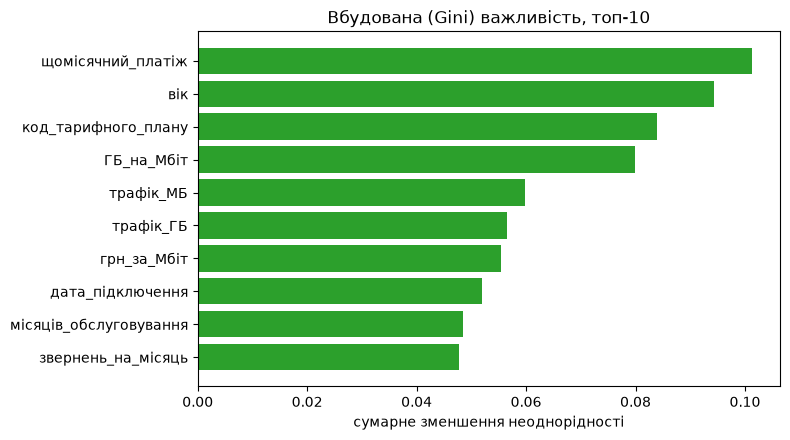

,вбудована важливість
щомісячний_платіж,0.1013
вік,0.0944
код_тарифного_плану,0.0838
ГБ_на_Мбіт,0.0800
трафік_МБ,0.0598
трафік_ГБ,0.0565
грн_за_Мбіт,0.0554
дата_підключення,0.0519
місяців_обслуговування,0.0484
звернень_на_місяць,0.0477


In [30]:
# ----- ВАШ КОД -----
prep_ = model.named_steps['prep']
names = prep_.get_feature_names_out()

def to_original(name, columns=FINAL_X.columns):
    """'num__missingindicator_x' / 'num__x' / 'cat__x_рівень' -> 'x'."""
    n = name.split('__', 1)[1]
    n = n.replace('missingindicator_', '')
    if n in columns:
        return n
    cands = [c for c in columns if n.startswith(c + '_')]
    return max(cands, key=len)

gini_imp = (pd.Series(model.named_steps['clf'].feature_importances_, index=names)
            .groupby(lambda s: to_original(s)).sum().sort_values(ascending=False))

top = gini_imp.head(10)[::-1]
plt.figure(figsize=(8, 4.5))
plt.barh(top.index, top.values, color='tab:green')
plt.title('Вбудована (Gini) важливість, топ-10')
plt.xlabel('сумарне зменшення неоднорідності')
plt.tight_layout(); plt.show()
display(gini_imp.head(10).round(4).to_frame('вбудована важливість'))

### Завдання 9.2 — перестановочна важливість

Інший підхід: взяти навчену модель, **перемішати значення однієї ознаки**
у перевірковій частині й подивитись, наскільки впала якість. Впала сильно —
ознака потрібна; не впала — не потрібна.

Рахуйте на **перевірковій** частині: на навчальній перестановочна важливість
показує те саме перенавчання, що й вбудована.

In [31]:
perm = permutation_importance(model, Xte, yte, n_repeats=10,
                              random_state=SEED, scoring='roc_auc')
perm_imp = pd.Series(perm.importances_mean, index=FINAL_X.columns).sort_values(ascending=False)
display(perm_imp.head(10).to_frame('перестановочна важливість'))

,перестановочна важливість
вік,0.081546
місяців_обслуговування,0.016484
трафік_МБ,0.008697
звернень_на_місяць,0.006162
ГБ_на_Мбіт,0.005293
щомісячний_платіж,0.005266
аварій_на_ділянці_за_квартал,0.003865
тариф,0.003779
трафік_ГБ,0.003549
дата_підключення,0.003291


### Завдання 9.3 — ПЕРША ХИБНА ІНТЕРПРЕТАЦІЯ

Порівняйте два списки поруч. Знайдіть ознаку, яка:

* входить у **топ-5 за вбудованою** важливістю;
* має перестановочну важливість **близьку до нуля або від'ємну**.

Така ознака є в кожному варіанті. Знайдіть її, назвіть і поясніть, чому
вбудована важливість її переоцінює.

> **Підказка.** Згадайте, як дерево обирає розбиття. Ознака з великою
> кількістю різних значень дає дереву багато можливих порогів, тож вона
> майже завжди знаходить розбиття, яке трохи зменшує неоднорідність —
> навіть якщо жодного зв'язку з ціллю немає.

In [32]:
# ----- ВАШ КОД: таблиця «ознака | вбудована | перестановочна», відсортована за вбудованою -----
imp_cmp = pd.DataFrame({'вбудована': gini_imp, 'перестановочна': perm_imp})
imp_cmp['ранг_вбудована'] = imp_cmp['вбудована'].rank(ascending=False).astype(int)
imp_cmp['ранг_перестановочна'] = imp_cmp['перестановочна'].rank(ascending=False).astype(int)
imp_cmp['унікальних_значень'] = [FINAL_X[c].nunique() for c in imp_cmp.index]
imp_cmp = imp_cmp.sort_values('вбудована', ascending=False)
display(imp_cmp.head(12).round(4))

,вбудована,перестановочна,ранг_вбудована,ранг_перестановочна,унікальних_значень
щомісячний_платіж,0.1013,0.0053,1,6,1122
вік,0.0944,0.0815,2,1,61
код_тарифного_плану,0.0838,0.0003,3,17,40
ГБ_на_Мбіт,0.0800,0.0053,4,5,1056
трафік_МБ,0.0598,0.0087,5,3,1200
трафік_ГБ,0.0565,0.0035,6,9,951
грн_за_Мбіт,0.0554,-0.0022,7,25,1147
дата_підключення,0.0519,0.0033,8,10,599
місяців_обслуговування,0.0484,0.0165,9,2,79
звернень_на_місяць,0.0477,0.0062,10,4,139


In [33]:
FAKE_IMPORTANT = 'код_тарифного_плану'        # назва ознаки
FAKE_IMPORTANT_WHY = (
    'це категорія з 40 рівнями (по 21-38 клієнтів), яка після одиничного кодування дає 40 '
    'дамі-стовпців; кожен з них дерево може використати для розбиття, і в малих вузлах якийсь'
    ' із них завжди трохи зменшує Gini випадково; після підсумовування 40 дрібних внесків '
    'ознака посідає 3-тє місце за вбудованою важливістю (0,084), хоча перестановка на '
    "перевірковій частині майже не погіршує AUC (0,0003, 17-те місце) - корисного зв'язку з "
    'відтоком немає.'
)    # чому вбудована важливість її переоцінює
assert FAKE_IMPORTANT in FINAL_X.columns and FAKE_IMPORTANT_WHY
print('хибно важлива ознака:', FAKE_IMPORTANT)

хибно важлива ознака: код_тарифного_плану


### Завдання 9.4 — ДРУГА ХИБНА ІНТЕРПРЕТАЦІЯ

У наборі є **дві ознаки, які вимірюють те саме в різних одиницях**.
Знайдіть цю пару (підказка: подивіться на кореляції між числовими ознаками).

Потім перевірте, що з нею робить перестановочна важливість:

1. запишіть важливість обох ознак пари в повній моделі;
2. **приберіть одну** з них, навчіть модель заново і подивіться на важливість
   тієї, що лишилась.

Поясніть, що сталось і чому.

In [34]:
# ----- ВАШ КОД: кореляційна матриця числових ознак, знайдіть пару з |r| > 0.97 -----
num_cols = [c for c in FINAL_X.columns if str(FINAL_X[c].dtype) != 'category']
corr = FINAL_X[num_cols].corr()
pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
         .rename('r').reset_index().rename(columns={'level_0': 'ознака_1', 'level_1': 'ознака_2'}))
pairs = pairs.reindex(pairs['r'].abs().sort_values(ascending=False).index)
display(pairs.head(6).round(4))
print('пари з |r| > 0.97:')
display(pairs[pairs['r'].abs() > 0.97].round(4))

,ознака_1,ознака_2,r
118,трафік_ГБ,трафік_МБ,0.9997
105,знижка_відсоток,є_знижка,0.8844
142,кількість_звернень_у_підтримку,проблем_сервісу,0.7578
58,швидкість_тарифу_Мбіт,щомісячний_платіж,0.7287
251,грн_за_Мбіт,ГБ_на_Мбіт,0.7006
67,швидкість_тарифу_Мбіт,грн_за_Мбіт,-0.6609


пари з |r| > 0.97:


,ознака_1,ознака_2,r
118,трафік_ГБ,трафік_МБ,0.9997


In [35]:
DUP_PAIR = ['трафік_ГБ', 'трафік_МБ']        # дві ознаки, що вимірюють те саме
assert all(c in FINAL_X.columns for c in DUP_PAIR) and DUP_PAIR[0] != DUP_PAIR[1]

print('у повній моделі:')
for c in DUP_PAIR:
    print('   %-28s %+.4f' % (c, perm_imp[c]))

# ----- ВАШ КОД: приберіть DUP_PAIR[1], навчіть заново, порахуйте перестановочну -----
# і виведіть важливість DUP_PAIR[0] без пари
Xtr_d, Xte_d = Xtr.drop(columns=DUP_PAIR[1]), Xte.drop(columns=DUP_PAIR[1])
model_d = make_pipe(Xtr_d, RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)).fit(Xtr_d, ytr)
perm_d = permutation_importance(model_d, Xte_d, yte, n_repeats=10, random_state=SEED, scoring='roc_auc')
perm_imp_d = pd.Series(perm_d.importances_mean, index=Xte_d.columns).sort_values(ascending=False)
print()
print('без %s:' % DUP_PAIR[1])
print('   %-28s %+.4f   (місце %d з %d)' % (DUP_PAIR[0], perm_imp_d[DUP_PAIR[0]],
      list(perm_imp_d.index).index(DUP_PAIR[0]) + 1, len(perm_imp_d)))
print('AUC моделі без пари на відкладеній: %.3f (з парою %.3f)'
      % (roc_auc_score(yte, model_d.predict_proba(Xte_d)[:, 1]), auc_hold))

у повній моделі:
   трафік_ГБ                    +0.0035
   трафік_МБ                    +0.0087

без трафік_МБ:
   трафік_ГБ                    +0.0119   (місце 4 з 24)
AUC моделі без пари на відкладеній: 0.800 (з парою 0.800)


In [36]:
DUP_EXPLANATION = (
    'трафік_МБ - це той самий трафік_ГБ, помножений на ~1024 (r = 0,9997). У повній моделі '
    'перестановочна важливість ділиться між ними: 0,0035 у ГБ і 0,0087 у МБ, бо коли '
    'перемішуєш одну, ліс бере ту саму інформацію з другої. Без трафік_МБ важливість '
    'трафік_ГБ зросла в 3,4 рази (до 0,0119, 4-те місце з 24), а AUC моделі не змінилась '
    '(0,800). Висновок «обидві майже нульові - викинемо обидві» був би хибним: разом вони '
    'несуть помітний сигнал.'
)
assert DUP_EXPLANATION
print(DUP_EXPLANATION)

трафік_МБ - це той самий трафік_ГБ, помножений на ~1024 (r = 0,9997). У повній моделі перестановочна важливість ділиться між ними: 0,0035 у ГБ і 0,0087 у МБ, бо коли перемішуєш одну, ліс бере ту саму інформацію з другої. Без трафік_МБ важливість трафік_ГБ зросла в 3,4 рази (до 0,0119, 4-те місце з 24), а AUC моделі не змінилась (0,800). Висновок «обидві майже нульові - викинемо обидві» був би хибним: разом вони несуть помітний сигнал.


> **Що тут сталося.** Перестановочна важливість відповідає на питання
> «наскільки модель погіршиться **без цієї ознаки**». Коли та сама інформація
> є у двох колонках, перемішування однієї нічого не ламає: модель бере її
> з другої. Обидві виглядають непотрібними — хоча разом вони важливі.
>
> Це не вада методу, а точна відповідь на поставлене питання. Вада —
> в інтерпретації «важливість нуль, отже ознаку можна викинути».

---
## 10. Графіки часткової залежності

Важливість каже, **наскільки** ознака потрібна. Вона не каже, **як саме**
ознака впливає: більше — ризикованіше чи навпаки.

**Графік часткової залежності (PDP)** будується так: беремо всю вибірку,
підставляємо всім клієнтам одне й те саме значення ознаки, усереднюємо
прогноз; повторюємо для сітки значень.

### Завдання 10.1

Побудуйте PDP для трьох найважливіших **числових** ознак за перестановочною
важливістю. Для кожної скажіть словами, що означає форма кривої.

три найважливіші числові ознаки: ['вік', 'місяців_обслуговування', 'трафік_МБ']


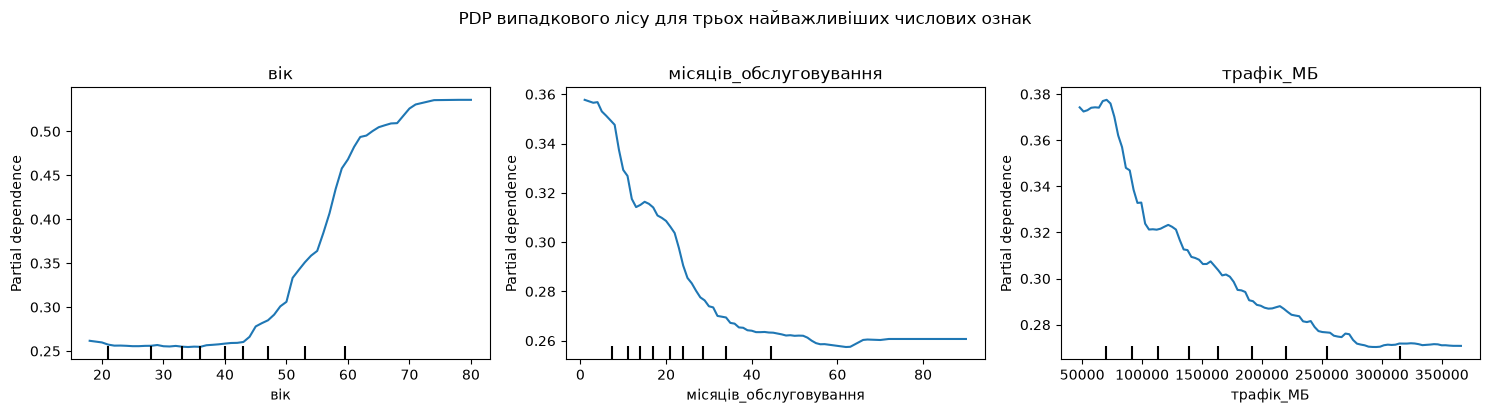

In [37]:
from sklearn.inspection import PartialDependenceDisplay

# ----- ВАШ КОД -----
num_perm = [c for c in perm_imp.index if str(FINAL_X[c].dtype) != 'category']
TOP3_NUM = num_perm[:3]
print('три найважливіші числові ознаки:', TOP3_NUM)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, f in zip(axes, TOP3_NUM):
    sub = Xte[Xte[f].notna()]
    PartialDependenceDisplay.from_estimator(model, sub, features=[f], kind='average', ax=ax)
    ax.set_title(f)
plt.suptitle('PDP випадкового лісу для трьох найважливіших числових ознак', y=1.02)
plt.tight_layout(); plt.show()

### Завдання 10.2 — немонотонна залежність

Серед ознак є така, у якої PDP **не монотонний**: ризик спадає, а потім
знову зростає (або навпаки). Знайдіть її.

Лінійна модель такої залежності не бачить **за побудовою**: вона може лише
зростати або лише спадати. Перевірте це: порівняйте PDP лісу й логістичної
регресії на тій самій ознаці, на одному рисунку.

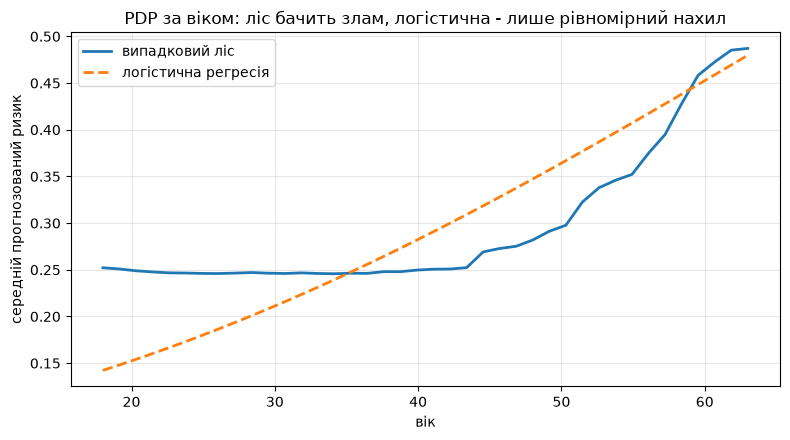

ризик за лісом мінімальний при вік ≈ 34


вік,"(17.934, 26.25]","(26.25, 34.5]","(34.5, 42.75]","(42.75, 51.0]","(51.0, 59.25]","(59.25, 67.5]","(67.5, 75.75]","(75.75, 84.0]"
клієнтів,226.000,220.000,268.00,250.000,143.000,62.000,24.00,7.0
частка відтоку,0.217,0.209,0.19,0.248,0.441,0.645,0.75,1.0


In [38]:
NONLINEAR_FEATURE = 'вік'
assert NONLINEAR_FEATURE in FINAL_X.columns

model_lr = make_pipe(FINAL_X, logreg()).fit(Xtr, ytr)
sub = FINAL_X[FINAL_X[NONLINEAR_FEATURE].notna()]
pd_rf = partial_dependence(model, sub, [NONLINEAR_FEATURE], kind='average', grid_resolution=40)
pd_lr = partial_dependence(model_lr, sub, [NONLINEAR_FEATURE], kind='average', grid_resolution=40)
grid = pd_rf['grid_values'][0]

plt.figure(figsize=(8, 4.5))
plt.plot(grid, pd_rf['average'][0], lw=2, label='випадковий ліс')
plt.plot(pd_lr['grid_values'][0], pd_lr['average'][0], lw=2, ls='--', label='логістична регресія')
plt.xlabel(NONLINEAR_FEATURE); plt.ylabel('середній прогнозований ризик')
plt.title('PDP за віком: ліс бачить злам, логістична - лише рівномірний нахил')
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()
X_MIN_RISK = float(grid[np.argmin(pd_rf['average'][0])])
print('ризик за лісом мінімальний при %s ≈ %.0f' % (NONLINEAR_FEATURE, X_MIN_RISK))

bins = pd.cut(FINAL_X[NONLINEAR_FEATURE], 8)
display(y.groupby(bins, observed=True).agg(['size', 'mean']).round(3)
        .rename(columns={'size': 'клієнтів', 'mean': 'частка відтоку'}).T)

In [39]:
NONLINEAR_MEANING = (
    'вік: ризик відтоку трохи вищий у наймолодших (18-25 років, 22 %), мінімальний у 30-45 '
    'років (~20 %), а після 50 різко зростає (51-55 - 39 %, 56-60 - 52 %, понад 60 - 72 %): '
    'люди середнього віку найстабільніші абоненти, а старші клієнти йдуть найчастіше (переїзд'
    ' до дітей, відмова від домашнього інтернету, перехід на дешевший мобільний).'
)     # що означає ця форма змістовно, мовою предметної області
NONLINEAR_FIX = (
    'додати ознаку (вік - 34)² - квадрат відхилення від віку мінімального ризику; тоді '
    'лінійна модель може описати і підйом ліворуч, і крутий ріст праворуч.'
)         # яку ознаку треба сконструювати, щоб лінійна модель це побачила
assert NONLINEAR_MEANING and NONLINEAR_FIX
print(NONLINEAR_MEANING)
print(NONLINEAR_FIX)

вік: ризик відтоку трохи вищий у наймолодших (18-25 років, 22 %), мінімальний у 30-45 років (~20 %), а після 50 різко зростає (51-55 - 39 %, 56-60 - 52 %, понад 60 - 72 %): люди середнього віку найстабільніші абоненти, а старші клієнти йдуть найчастіше (переїзд до дітей, відмова від домашнього інтернету, перехід на дешевший мобільний).
додати ознаку (вік - 34)² - квадрат відхилення від віку мінімального ризику; тоді лінійна модель може описати і підйом ліворуч, і крутий ріст праворуч.


### Завдання 10.2б — замкніть цикл

Пояснення моделі має **повертатись у підготовку даних**. PDP показав форму —
тепер побудуйте ознаку цієї форми і виміряйте, що вона дала.

Зробіть це для **логістичної регресії**, а не для лісу: ліс цю форму і так
бачив, а лінійна модель — ні. Порівняння має бути парним.

In [40]:
# ----- ВАШ КОД -----
# 1) зчитайте з графіка значення, при якому ризик мінімальний;
print('мінімум ризику: %s ≈ %.0f' % (NONLINEAR_FEATURE, X_MIN_RISK))
# 2) додайте ознаку «квадрат відхилення від цього значення»;
X5q = FINAL_X.copy()
X5q[NONLINEAR_FEATURE + '_відхил²'] = (X5q[NONLINEAR_FEATURE] - X_MIN_RISK) ** 2
# 3) парне порівняння логістичної регресії з нею і без неї.
auc_lr_base = cross_val_score(make_pipe(FINAL_X, logreg()), FINAL_X, y, cv=cv, scoring='roc_auc')
auc_lr_quad = cross_val_score(make_pipe(X5q, logreg()), X5q, y, cv=cv, scoring='roc_auc')
mq, hq = paired(auc_lr_base, auc_lr_quad)
print('логістична без ознаки : AUC %.4f ± %.4f' % (auc_lr_base.mean(), auc_lr_base.std()))
print('логістична з ознакою  : AUC %.4f ± %.4f' % (auc_lr_quad.mean(), auc_lr_quad.std()))
print('приріст: %+0.4f ± %.4f   %s' % (mq, hq, 'значуще' if abs(mq) > hq else 'у межах шуму'))

мінімум ризику: вік ≈ 34
логістична без ознаки : AUC 0.8098 ± 0.0264
логістична з ознакою  : AUC 0.8362 ± 0.0297
приріст: +0.0264 ± 0.0054   значуще


In [41]:
QUAD_GAIN = mq     # приріст AUC лінійної моделі від нової ознаки
assert QUAD_GAIN is not None
print('приріст від сконструйованої ознаки: %+.4f' % QUAD_GAIN)

приріст від сконструйованої ознаки: +0.0264


### Завдання 10.3 — ТРЕТЯ ХИБНА ІНТЕРПРЕТАЦІЯ

PDP **усереднює по всій вибірці**. Якщо ознака діє на різні групи клієнтів
по-різному, усереднення це приховає: протилежні ефекти взаємно погасяться,
і крива вийде майже пласкою.

Перевірте це на парі «знижка — стаж обслуговування».

1. Побудуйте звичайний PDP для `знижка_відсоток` по всій вибірці.
2. Побудуйте **ICE** (`kind='individual'`) — по кривій на кожного клієнта.
   Подивіться, чи всі криві йдуть в один бік.
3. Побудуйте PDP для `знижка_відсоток` **окремо** на двох підвибірках:
   клієнти зі стажем до 24 місяців і понад 24 місяці.

> **Важливо.** PDP і ICE рахуйте на **повній** матриці `FINAL_X`,
> а не на `Xte`. Це опитування моделі, а не оцінювання якості, тож
> використовувати всі рядки коректно — а на 30 % рядків підгрупи виходять
> замалі й криві стають шумними.

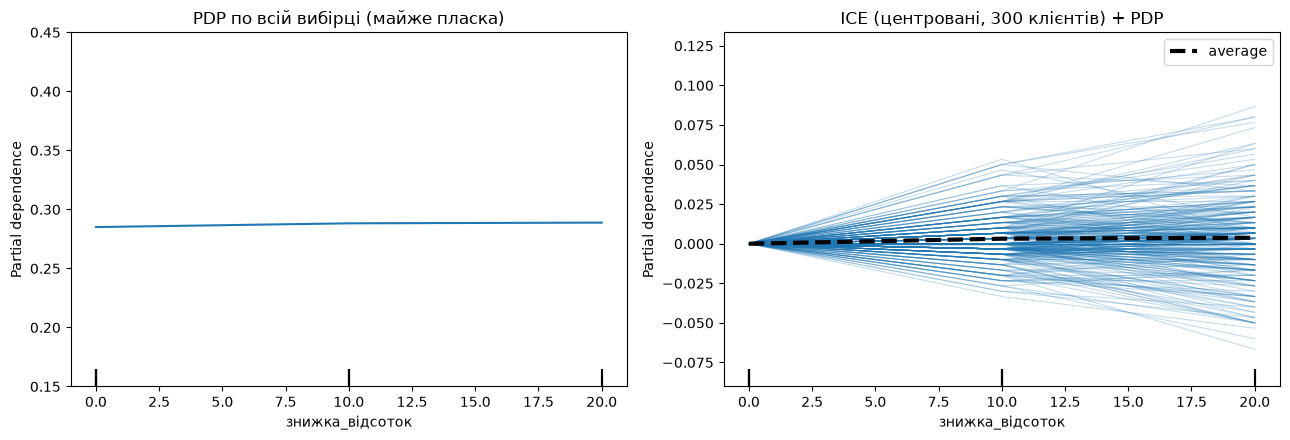

ефект знижки 0% -> 20% на окремих клієнтів:
   ризик падає  : 182 клієнтів (15 %)
   ризик росте  : 255 клієнтів (21 %)
   середній ефект (те, що показує PDP): +0.004


In [42]:
# ----- ВАШ КОД: пункт 1 і 2, PDP та ICE для 'знижка_відсоток' -----
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
d0 = PartialDependenceDisplay.from_estimator(model, FINAL_X, features=['знижка_відсоток'],
                                             kind='average', ax=ax[0])
d0.axes_[0, 0].set_ylim(0.15, 0.45)
d0.axes_[0, 0].set_title('PDP по всій вибірці (майже пласкa)')
PartialDependenceDisplay.from_estimator(model, FINAL_X, features=['знижка_відсоток'],
                                        kind='both', subsample=300, random_state=SEED,
                                        centered=True, ax=ax[1],
                                        ice_lines_kw={'alpha': 0.25, 'lw': 0.8},
                                        pd_line_kw={'color': 'k', 'lw': 3})
ax[1].set_title('ICE (центровані, 300 клієнтів) + PDP')
plt.tight_layout(); plt.show()

ice = partial_dependence(model, FINAL_X, ['знижка_відсоток'], kind='individual')
eff = ice['individual'][0][:, -1] - ice['individual'][0][:, 0]
print('ефект знижки 0% -> 20% на окремих клієнтів:')
print('   ризик падає  : %d клієнтів (%.0f %%)' % ((eff < -0.02).sum(), 100 * (eff < -0.02).mean()))
print('   ризик росте  : %d клієнтів (%.0f %%)' % ((eff > 0.02).sum(), 100 * (eff > 0.02).mean()))
print('   середній ефект (те, що показує PDP): %+.3f' % eff.mean())

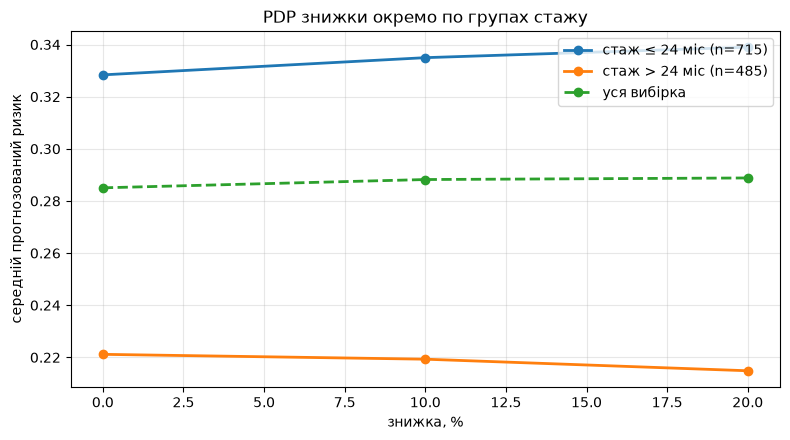

In [43]:
# ----- ВАШ КОД: пункт 3, дві криві на одному рисунку -----
young = FINAL_X['місяців_обслуговування'] <= 24
plt.figure(figsize=(8, 4.5))
for mask, lbl in [(young, 'стаж ≤ 24 міс (n=%d)' % young.sum()),
                  (~young, 'стаж > 24 міс (n=%d)' % (~young).sum()),
                  (slice(None), 'уся вибірка')]:
    r = partial_dependence(model, FINAL_X[mask], ['знижка_відсоток'], kind='average')
    plt.plot(r['grid_values'][0], r['average'][0], marker='o', lw=2,
             ls='--' if lbl == 'уся вибірка' else '-', label=lbl)
plt.xlabel('знижка, %'); plt.ylabel('середній прогнозований ризик')
plt.title('PDP знижки окремо по групах стажу')
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

### Завдання 10.3б — звірка з сирими даними

Перш ніж вірити графіку, перевірте його по сирій таблиці: порахуйте
**емпіричну** частку відтоку за розміром знижки окремо в кожній групі стажу.
Модель має відтворювати ту саму картину. Якщо не відтворює — питання
не до PDP, а до моделі.

In [44]:
# ----- ВАШ КОД: зведена таблиця «знижка x група стажу» -> частка відтоку і розмір групи -----
grp = np.where(raw['місяців_обслуговування'] <= 24, 'стаж ≤ 24', 'стаж > 24')
emp = raw.assign(група_стажу=grp).pivot_table(index='знижка_відсоток', columns='група_стажу',
                                               values=TARGET, aggfunc=['mean', 'size'])
emp.columns = ['%s | %s' % ('частка відтоку' if a == 'mean' else 'клієнтів', b) for a, b in emp.columns]
display(emp.round(3))

,частка відтоку | стаж > 24,частка відтоку | стаж ≤ 24,клієнтів | стаж > 24,клієнтів | стаж ≤ 24
знижка_відсоток,,,,
0,0.235,0.269,221,290
10,0.142,0.376,134,250
20,0.069,0.480,130,175


In [45]:
INTERACTION_FOUND = (
    'у сирих даних знижка діє протилежно у двох групах: у клієнтів зі стажем понад 24 місяці '
    'відтік падає з 23,5 % без знижки до 14,2 % при 10 % і до 6,9 % при 20 %; у новачків '
    '(стаж до 24 місяців) відтік, навпаки, росте: 26,9 % -> 37,6 % -> 48,0 %. По всій вибірці'
    ' ефекти гасять один одного, і PDP майже пласкa (+0,004 від 0 до 20 %); ICE показують '
    'розбіжність: у 15 % клієнтів ризик падає, у 21 % - росте. Модель відтворює напрям у '
    'групах, але сильно його згладжує (новачки 0,33 -> 0,34, старожили 0,22 -> 0,21), тобто '
    'взаємодію ліс уловив слабко.'
)     # опишіть, що робить знижка в кожній із двох груп
BUSINESS_ACTION = (
    'знижку варто пропонувати лише лояльним клієнтам зі стажем понад 2 роки; новачкам знижка '
    'не допомагає (ймовірно, її дають уже незадоволеним, або вона приваблює «мисливців за '
    "акціями»), тож для них потрібні інші заходи - перевірка якості зв'язку, правильний "
    'тариф; рішення про знижку слід ухвалювати з урахуванням стажу, а не за середнім PDP.'
)       # що з цього випливає для відділу утримання
assert INTERACTION_FOUND and BUSINESS_ACTION
print(INTERACTION_FOUND)
print(BUSINESS_ACTION)

у сирих даних знижка діє протилежно у двох групах: у клієнтів зі стажем понад 24 місяці відтік падає з 23,5 % без знижки до 14,2 % при 10 % і до 6,9 % при 20 %; у новачків (стаж до 24 місяців) відтік, навпаки, росте: 26,9 % -> 37,6 % -> 48,0 %. По всій вибірці ефекти гасять один одного, і PDP майже пласкa (+0,004 від 0 до 20 %); ICE показують розбіжність: у 15 % клієнтів ризик падає, у 21 % - росте. Модель відтворює напрям у групах, але сильно його згладжує (новачки 0,33 -> 0,34, старожили 0,22 -> 0,21), тобто взаємодію ліс уловив слабко.
знижку варто пропонувати лише лояльним клієнтам зі стажем понад 2 роки; новачкам знижка не допомагає (ймовірно, її дають уже незадоволеним, або вона приваблює «мисливців за акціями»), тож для них потрібні інші заходи - перевірка якості зв'язку, правильний тариф; рішення про знижку слід ухвалювати з урахуванням стажу, а не за середнім PDP.


> **Що тут сталося.** PDP відповідає на питання «як змінюється
> **середній** прогноз». Якщо ефект різноспрямований, середнє близьке до нуля
> при сильних ефектах у кожній групі. ICE показує окремі криві й робить
> розбіжність видимою; PDP по підгрупах показує її кількісно.

---
## 11. Значення Шеплі

Важливість і PDP описують модель **загалом**. Відділу утримання потрібне
інше: чому **цей** клієнт отримав оцінку 0,8.

**Значення Шеплі** (SHAP) розкладають прогноз для одного об'єкта на внески
окремих ознак так, щоб сума внесків плюс базовий рівень дорівнювала самому
прогнозу. Ідея запозичена з теорії кооперативних ігор: внесок гравця —
це його середній приріст до результату по всіх можливих складах команди.

### Завдання 11.1

Порахуйте значення Шеплі для вашої моделі на перевірковій частині.

> `TreeExplainer` працює з деревами і хоче **числову матрицю**, тому
> подавайте йому вже перетворені дані: `model.named_steps['prep'].transform(Xte)`.

In [46]:
import shap

prep = model.named_steps['prep']
clf = model.named_steps['clf']
Xte_t = prep.transform(Xte)
feat_names = prep.get_feature_names_out()

SAMPLE = min(300, Xte_t.shape[0])      # щоб рахувалось за секунди
expl = shap.TreeExplainer(clf)
sv = expl.shap_values(Xte_t[:SAMPLE])
sv1 = sv[..., 1] if (hasattr(sv, 'ndim') and sv.ndim == 3) else sv
print('матриця значень Шеплі:', np.shape(sv1))

матриця значень Шеплі: (300, 84)


### Завдання 11.2 — зведений графік

Побудуйте `beeswarm` (`shap.summary_plot`). Прочитайте з нього дві речі,
яких **не дає** стовпчикова діаграма важливості:

* у який бік діє ознака (колір — значення ознаки, вісь — внесок);
* чи однаковий цей напрям для всіх клієнтів.

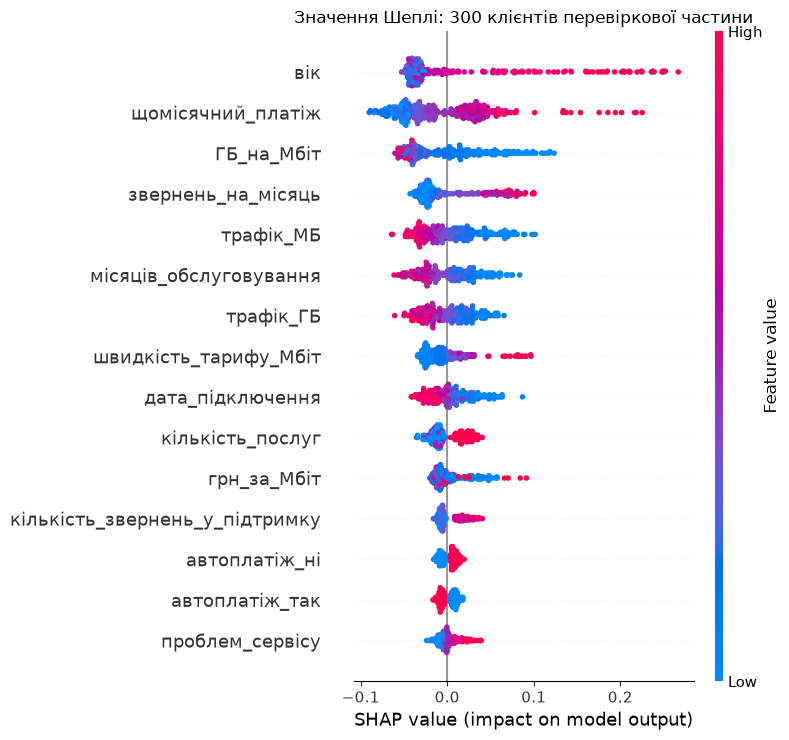

,середній |SHAP|
вік,0.0548
щомісячний_платіж,0.0446
ГБ_на_Мбіт,0.0375
звернень_на_місяць,0.0318
трафік_МБ,0.0270
місяців_обслуговування,0.0257
трафік_ГБ,0.0224
швидкість_тарифу_Мбіт,0.0187
дата_підключення,0.0174
кількість_послуг,0.0165


In [47]:
# ----- ВАШ КОД: shap.summary_plot(sv1, Xte_t[:SAMPLE], feature_names=feat_names) -----
short = [n.split('__', 1)[1] for n in feat_names]
shap.summary_plot(sv1, Xte_t[:SAMPLE], feature_names=short, max_display=15, show=False)
plt.title('Значення Шеплі: 300 клієнтів перевіркової частини')
plt.tight_layout(); plt.show()

mean_abs = pd.Series(np.abs(sv1).mean(0), index=short).sort_values(ascending=False)
display(mean_abs.head(10).round(4).to_frame('середній |SHAP|'))

### Завдання 11.3 — пояснення для одного клієнта

Відділ утримання телефонує конкретній людині. Візьміть клієнта з
**найвищою** оцінкою ризику і поясніть його прогноз: які три ознаки
внесли найбільше і в який бік.

Напишіть пояснення **мовою, якою його можна прочитати менеджерові**, —
без назв стовпців і без слова «модель».

In [48]:
idx = int(np.argmax(model.predict_proba(Xte)[:SAMPLE, 1]))
print('ризик клієнта: %.3f' % model.predict_proba(Xte)[:SAMPLE, 1][idx])

# ----- ВАШ КОД: три найбільші за модулем внески для цього клієнта -----
base_value = np.ravel(expl.expected_value)[-1]
contrib = pd.Series(sv1[idx], index=short)
top3 = contrib.reindex(contrib.abs().sort_values(ascending=False).index).head(3)
print('клієнт:', Xte.index[idx], '| базовий рівень %.3f' % base_value)
print('сума внесків + база = %.3f' % (base_value + contrib.sum()))
print()
for f, v in top3.items():
    orig = to_original('x__' + f)
    print('   %-35s %+.3f   (значення: %s)' % (f, v, Xte.iloc[idx][orig]))
print()
display(Xte.iloc[[idx]].T.rename(columns={Xte.index[idx]: 'значення'}))

ризик клієнта: 0.790
клієнт: 144 | базовий рівень 0.280
сума внесків + база = 0.790

   вік                                 +0.101   (значення: 57.0)
   ГБ_на_Мбіт                          +0.077   (значення: 0.11633333333333333)
   звернень_на_місяць                  +0.067   (значення: 0.1111111111111111)



,значення
вік,57.0
стать,ж
місто,червоноград
тариф,бізнес
тип_підключення,оптика
спосіб_оплати,картка
автоплатіж,так
кількість_послуг,3.0
місяців_обслуговування,17.0
швидкість_тарифу_Мбіт,600.0


In [49]:
EXPLANATION_FOR_MANAGER = (
    'Клієнтка 57 років з Червонограда, обслуговується 17 місяців; ризик її відходу - близько '
    '79 % проти 28 % у середньому. Найбільше ризик підвищують три речі: 1) вік - клієнти, '
    'старші за 50, ідуть удвічі частіше за інших (53 % проти 21 %); 2) вона майже не '
    'користується швидкістю, за яку платить: 70 ГБ на місяць на тарифі 600 Мбіт/с - це '
    'приблизно в 7 разів менше на кожен Мбіт/с, ніж у типового абонента, тобто вона '
    'переплачує за непотрібну швидкість (427 грн на місяць); 3) двічі зверталась у підтримку '
    'за 17 місяців. Знижка 20 % у неї вже є, тож пропонувати ще знижку марно - доречніше '
    "запропонувати дешевший тариф із меншою швидкістю і з'ясувати, чи вирішено її звернення."
)
assert EXPLANATION_FOR_MANAGER
print(EXPLANATION_FOR_MANAGER)

Клієнтка 57 років з Червонограда, обслуговується 17 місяців; ризик її відходу - близько 79 % проти 28 % у середньому. Найбільше ризик підвищують три речі: 1) вік - клієнти, старші за 50, ідуть удвічі частіше за інших (53 % проти 21 %); 2) вона майже не користується швидкістю, за яку платить: 70 ГБ на місяць на тарифі 600 Мбіт/с - це приблизно в 7 разів менше на кожен Мбіт/с, ніж у типового абонента, тобто вона переплачує за непотрібну швидкість (427 грн на місяць); 3) двічі зверталась у підтримку за 17 місяців. Знижка 20 % у неї вже є, тож пропонувати ще знижку марно - доречніше запропонувати дешевший тариф із меншою швидкістю і з'ясувати, чи вирішено її звернення.


### Завдання 11.4 — ЧЕТВЕРТА ХИБНА ІНТЕРПРЕТАЦІЯ

Менеджер читає ваше пояснення і каже:

> «Зрозуміло. Значення Шеплі кажуть, що ризик тягне нагору
> **{ознака}**. Змінимо її — і клієнт лишиться».

Це найпоширеніша і найдорожча помилка в інтерпретації. Значення Шеплі
показують, **як модель користується ознакою**, а не **що станеться, якщо
ознаку змінити**. Це різні твердження, і друге з них вимагає причинного
висновку, якого в даних немає.

Наведіть із **свого** набору конкретний приклад: ознака з великим внеском,
втручання в яку нічого не дасть. Поясніть чому.

In [50]:
SHAP_NOT_CAUSAL_FEATURE = 'ГБ_на_Мбіт'
SHAP_NOT_CAUSAL_WHY = (
    'низьке використання каналу (мало ГБ на кожен оплачений Мбіт/с) - третя за внеском ознака'
    ' за Шеплі (середній |SHAP| 0,038) і друга у найризикованішої клієнтки (+0,077), але це '
    'симптом, а не причина: людина, яка вже користується мобільним інтернетом або іншим '
    'провайдером, споживає менше трафіку саме тому, що збирається піти. Якщо «підняти» їй '
    'трафік (дати бонусні ГБ) або змусити користуватись, причина відходу не зникне. Те саме з'
    ' віком - він має найбільший внесок (0,055), але змінити його неможливо взагалі. Шеплі '
    'кажуть, як модель використовує ознаку для прогнозу, а не що станеться, якщо втрутитися.'
)
assert SHAP_NOT_CAUSAL_FEATURE and SHAP_NOT_CAUSAL_WHY
print(SHAP_NOT_CAUSAL_FEATURE, '—', SHAP_NOT_CAUSAL_WHY)

ГБ_на_Мбіт — низьке використання каналу (мало ГБ на кожен оплачений Мбіт/с) - третя за внеском ознака за Шеплі (середній |SHAP| 0,038) і друга у найризикованішої клієнтки (+0,077), але це симптом, а не причина: людина, яка вже користується мобільним інтернетом або іншим провайдером, споживає менше трафіку саме тому, що збирається піти. Якщо «підняти» їй трафік (дати бонусні ГБ) або змусити користуватись, причина відходу не зникне. Те саме з віком - він має найбільший внесок (0,055), але змінити його неможливо взагалі. Шеплі кажуть, як модель використовує ознаку для прогнозу, а не що станеться, якщо втрутитися.


> **Орієнтир.** Ознаки бувають трьох видів: ті, на які можна вплинути
> (знижка, швидкість тарифу, швидкість реакції підтримки); ті, на які
> вплинути не можна (вік, місто, стаж); і ті, що є **наслідком** чогось
> іншого. Дія має сенс лише для першого виду — і лише якщо у вас є підстави
> вважати зв'язок причинним, а не збігом.

---
## 12. Зведення: чотири хибні інтерпретації

### Завдання 12.1

Заповніть таблицю своїми знахідками. Це головний результат другої частини.

In [51]:
mistakes = pd.DataFrame([
    {'№': 1, 'інструмент': 'вбудована важливість',
     'хибний висновок': 'ознака важлива, бо дерево часто по ній ріже',
     'ознака у вашому наборі': FAKE_IMPORTANT,
     'чим перевірити': 'перестановочна важливість на перевірковій частині'},
    {'№': 2, 'інструмент': 'перестановочна важливість',
     'хибний висновок': 'важливість нуль, отже ознаку можна викинути',
     'ознака у вашому наборі': ' + '.join(DUP_PAIR),
     'чим перевірити': 'прибрати одну з пари й переобчислити'},
    {'№': 3, 'інструмент': 'PDP',
     'хибний висновок': 'крива пласка, отже ознака не діє',
     'ознака у вашому наборі': 'знижка_відсоток',
     'чим перевірити': 'ICE або PDP окремо по підгрупах'},
    {'№': 4, 'інструмент': 'значення Шеплі',
     'хибний висновок': 'великий внесок, отже зміна ознаки змінить результат',
     'ознака у вашому наборі': SHAP_NOT_CAUSAL_FEATURE,
     'чим перевірити': 'питання, чи можна на цю ознаку вплинути взагалі'},
]).set_index('№')
display(mistakes)

,інструмент,хибний висновок,ознака у вашому наборі,чим перевірити
№,,,,
1,вбудована важливість,"ознака важлива, бо дерево часто по ній ріже",код_тарифного_плану,перестановочна важливість на перевірковій частині
2,перестановочна важливість,"важливість нуль, отже ознаку можна викинути",трафік_ГБ + трафік_МБ,прибрати одну з пари й переобчислити
3,PDP,"крива пласка, отже ознака не діє",знижка_відсоток,ICE або PDP окремо по підгрупах
4,значення Шеплі,"великий внесок, отже зміна ознаки змінить резу...",ГБ_на_Мбіт,"питання, чи можна на цю ознаку вплинути взагалі"


### Завдання 12.2 — п'ята, яку ви знайшли самі

Знайдіть у своєму аналізі ще один випадок, де пояснення можна прочитати
неправильно. Це може бути що завгодно: ознака-наслідок, що пройшла фільтри;
категорія з трьох спостережень і великим внеском; ознака, яка корелює
з артефактом збору. Опишіть його.

In [52]:
FIFTH_MISTAKE = (
    'Ознака дата_підключення має помітну вбудовану важливість (8-ме місце) і внесок за Шеплі '
    '(9-те місце, ранніше підключення -> вищий ризик), і її легко прочитати як «клієнти, '
    'підключені на початку 2023 року, ненадійні». Але поле суперечить стажу: усі дати лежать '
    'у 2023-2024 роках (максимум 24 місяці), тоді як місяців_обслуговування сягає 90, а '
    'кореляція між датою і стажем -0,007, хоча мала б бути майже -1. Отже поле означає не те,'
    ' що в назві (імовірно, дату переоформлення договору чи міграції в нову CRM), і будь-яка '
    'інтерпретація його внеску безпідставна; до того ж в 2023Q1 відтік 34 % проти 25-30 % '
    'далі - це може бути той самий артефакт збору (інший період запису), який ми бачили у '
    'філіях.'
)
assert FIFTH_MISTAKE and len(FIFTH_MISTAKE) > 40, 'опишіть докладніше'
print(FIFTH_MISTAKE)

Ознака дата_підключення має помітну вбудовану важливість (8-ме місце) і внесок за Шеплі (9-те місце, ранніше підключення -> вищий ризик), і її легко прочитати як «клієнти, підключені на початку 2023 року, ненадійні». Але поле суперечить стажу: усі дати лежать у 2023-2024 роках (максимум 24 місяці), тоді як місяців_обслуговування сягає 90, а кореляція між датою і стажем -0,007, хоча мала б бути майже -1. Отже поле означає не те, що в назві (імовірно, дату переоформлення договору чи міграції в нову CRM), і будь-яка інтерпретація його внеску безпідставна; до того ж в 2023Q1 відтік 34 % проти 25-30 % далі - це може бути той самий артефакт збору (інший період запису), який ми бачили у філіях.


---
## 13. Підсумкова модель і карта дій

### Завдання 13.1

Відділ утримання може обдзвонити **100 клієнтів на тиждень** — не більше.
Отже вам потрібна не «модель узагалі», а список зі ста прізвищ.

Відсортуйте перевіркову частину за оцінкою ризику спадно, візьміть перші 100
і порахуйте: скільки з них справді пішли? Порівняйте з тим, скільки ви
знайшли б, обираючи 100 клієнтів навмання.

In [53]:
# ----- ВАШ КОД -----
# lift = (частка відтоку серед топ-100) / (частка відтоку в усій перевірковій частині)
TOP_N = 100
risk = pd.Series(model.predict_proba(Xte)[:, 1], index=Xte.index)
top_ids = risk.sort_values(ascending=False).index[:TOP_N]
hit_top = int(yte.loc[top_ids].sum())
base_rate = yte.mean()
lift = (hit_top / TOP_N) / base_rate
print('у перевірковій частині %d клієнтів, пішли %d (%.1f %%)' % (len(yte), yte.sum(), 100 * base_rate))
print('серед топ-%d за ризиком пішли: %d (%.0f %%)' % (TOP_N, hit_top, 100 * hit_top / TOP_N))
print('навмання з %d вибрали б у середньому: %.1f' % (TOP_N, TOP_N * base_rate))
print('lift = %.2f' % lift)
print('частка всіх, хто пішов, охоплена списком: %.0f %%' % (100 * hit_top / yte.sum()))
br = raw.loc[top_ids, 'філія'].isin(SUSPECT_BRANCHES).mean()
print('частка клієнтів філій %s у топ-%d: %.0f %% (у всій перевірковій: %.0f %%)'
      % (SUSPECT_BRANCHES, TOP_N, 100 * br, 100 * raw.loc[Xte.index, 'філія'].isin(SUSPECT_BRANCHES).mean()))

у перевірковій частині 360 клієнтів, пішли 101 (28.1 %)
серед топ-100 за ризиком пішли: 60 (60 %)
навмання з 100 вибрали б у середньому: 28.1
lift = 2.14
частка всіх, хто пішов, охоплена списком: 59 %
частка клієнтів філій ['Ф-01 Центр', 'Ф-02 Захід'] у топ-100: 34 % (у всій перевірковій: 31 %)


In [54]:
LIFT_MEANING = (
    'Lift 2,14 означає: обдзвонюючи 100 клієнтів зі списку замість 100 випадкових, відділ '
    'утримання потрапить на 60 людей, що справді збираються піти, замість ~28, тобто кожен '
    'дзвінок у 2,1 раза результативніший, і за тиждень буде охоплено 59 % усіх, хто піде.'
)    # що число lift означає для бізнесу, одним реченням
assert LIFT_MEANING
print(LIFT_MEANING)

Lift 2,14 означає: обдзвонюючи 100 клієнтів зі списку замість 100 випадкових, відділ утримання потрапить на 60 людей, що справді збираються піти, замість ~28, тобто кожен дзвінок у 2,1 раза результативніший, і за тиждень буде охоплено 59 % усіх, хто піде.


> **Чому це важливіше за AUC.** AUC описує модель на всьому діапазоні
> порогів. Замовник працює в одній точці цього діапазону — там, де в нього
> вистачає людей на обдзвін. Звітуйте обидва числа.

---
## 14. Збереження результатів

In [55]:
result = {
    'студент': STUDENT_NAME,
    'номер': LIST_NUMBER,
    'варіант': VARIANT,
    'рішення': {'тип_задачі': TYPE_OF_TASK, 'метрика': METRIC, 'схема': CV_SCHEME},
    'знайдені_проблеми_даних': {
        'текст_у_числовій': PROBLEM_TEXT_IN_NUMBER,
        'excel_дата': PROBLEM_EXCEL_DATE,
        'mnar': PROBLEM_MNAR, 'сенс_пропуску': MNAR_MEANING},
    'витік': {'цільовий': TARGET_LEAK, 'оцінки_людини': HUMAN_LEAK,
              'чому_детектор_не_спіймав': HUMAN_LEAK_WHY},
    'артефакт': {'підозрюваний': SUSPECT, 'AUC_джерела': round(float(auc_src.mean()), 4),
                 'рішення': DECISION_ARTEFACT, 'аргумент': DECISION_WHY},
    'драбина_AUC': {k: round(float(v), 4) for k, v in
                    zip(ladder.index, ladder['AUC'].values)},
    'чесний_AUC': round(HONEST_AUC, 4),
    'обрана_модель': CHOSEN_MODEL,
    'хибні_інтерпретації': {
        'вбудована_важливість': FAKE_IMPORTANT,
        'дубльована_пара': DUP_PAIR,
        'нелінійна_ознака': NONLINEAR_FEATURE,
        'shap_не_причинність': SHAP_NOT_CAUSAL_FEATURE,
        'п_ята_власна': FIFTH_MISTAKE},
    'lift_топ100': None if lift is None else round(float(lift), 3),
}
with open('lr6_результат_%02d.json' % VARIANT, 'w', encoding='utf-8') as fh:
    json.dump(result, fh, ensure_ascii=False, indent=1)
print('збережено lr6_результат_%02d.json' % VARIANT)

збережено lr6_результат_02.json


---
## 15. Звіт

Відповідайте числами зі своїх обчислень, а не загальними словами.

1. **Яку метрику ви обрали і чому саме її?** Яку точність дала б модель
   «ніхто не піде» на ваших даних?
2. **Назвіть усі стовпці, які ви викинули**, і для кожного — момент часу,
   у який він з'являється. Який із них детектор із 5.1 не знайшов і чому?
3. **Яке ваше чесне число** і який у нього розкид? Що означає цей розкид
   для порівняння двох моделей, що відрізняються на 0,004?
4. **Чи є у ваших даних артефакт збору?** Наведіть AUC передбачення джерела
   і скажіть, чи можна цій моделі довіряти в іншій філії.
5. **Що дало більше — нові ознаки чи складніша модель?** Наведіть обидва
   прирости з довірчими інтервалами і час обчислень.
6. **Яку ознаку вбудована важливість назвала важливою помилково?**
   Чому дерева так роблять?
7. **Що сталося з дубльованою парою** при перестановочній важливості
   і чому це не вада методу?
8. **Яка ознака має немонотонний вплив?** Чи побачила б його логістична
   регресія без вашого втручання?
9. **Де PDP збрехав через усереднення** і що показав ICE?
10. **Наведіть приклад ознаки з великим внеском за Шеплі, втручання в яку
    нічого не дасть.** Поясніть різницю між «модель цим користується»
    і «це причина».
11. **Що ви скажете замовникові**, який просить за цією моделлю обдзвонити
    100 клієнтів? Назвіть lift і одне застереження.

### Декларація про використання штучного інтелекту

Зазначте, чи користувались ШІ-асистентом, для чого саме і що перевіряли
самостійно. Використання дозволене; невказане використання — ні.

In [56]:
REPORT = '''
1. Метрика - AUC. Частка відтоку 0,280 (336 з 1200), тому модель «ніхто не піде» дає точність 0,720,
   нічого не вміючи. AUC не залежить від порогу і дисбалансу і вимірює саме ранжування клієнтів за
   ризиком, яке потрібне для списку на обдзвін. Схема - стратифікована 5-кратна, 4 повтори (20 оцінок).

2. Викинуто: id_клієнта (ідентифікатор, лише запам'ятовується);
   код_причини_закриття і дата_розірвання - з'являються в момент розірвання договору, тобто після
   події, яку прогнозуємо (детектор 5.1: показник 1,000 - заповнені рівно у 336 клієнтів, що пішли);
   оцінка_ризику_менеджером - ставиться менеджером, коли той уже бачить наміри клієнта (оцінка 1 ->
   0 % відтоку, 5 -> 98 %); детектор її НЕ знайшов, бо вона заповнена у всіх 1200 клієнтів і витік
   сидить у значенні, а не в заповненості; філія - артефакт збору (див. п. 4).

3. Чесне число: AUC 0,813 ± 0,026 (логістична регресія, 20 оцінок), обраний випадковий ліс - 0,834 ± 0,029.
   Драбина: 1,000 (усе підряд) -> 0,966 (мінус цільовий витік) -> 0,863 (мінус оцінка менеджера) ->
   0,813 (мінус філія). Розкид 0,026 між згортками у 6 разів більший за 0,004, тому дві моделі, що
   відрізняються на 0,004, за середніми порівнювати не можна - лише парно на тих самих згортках, і
   навіть тоді така різниця зазвичай у межах шуму (інтервал парної різниці у нас ~±0,009).

4. Так. Частка відтоку стрибає сходинкою: Ф-01 Центр 0,440 і Ф-02 Захід 0,468 проти 0,191-0,212 в
   інших чотирьох філіях; за кварталами підключення зміна плавна (0,25-0,34). Ті самі чесні ознаки
   передбачають належність до двох підозрілих філій з AUC 0,641 - їхні клієнти дещо інші (молодші,
   більше оптики й оплати карткою), але не настільки, щоб пояснити подвоєння відтоку. Довіряти моделі
   в іншій (новій) філії можна обмежено: якщо там розірвання фіксують за «правилами» Ф-01/Ф-02,
   справжній відтік буде вдвічі вищим за прогноз; модель треба перевірити на даних цієї філії.

5. Складніша модель: випадковий ліс +0,0208 ± 0,0094, бустинг +0,0175 ± 0,0093 проти логістичної
   (обидва значущі) ціною ~31-37 с на 100 навчань замість ~2 с. П'ять нових ознак (грн за Мбіт,
   звернень на місяць, є знижка, сумарні проблеми сервісу, ГБ на Мбіт) дали логістичній
   -0,0031 ± 0,0014 (значуще гірше, ~2,5 с на 100 навчань) - вони дублюють наявну інформацію.
   Зате одна ознака, підказана PDP, - (вік - 34)² - дала логістичній +0,0264 ± 0,0054
   (0,810 -> 0,836) і без жодних витрат часу наздогнала ліс.

6. код_тарифного_плану: 3-тє місце за вбудованою важливістю (0,084), але перестановочна 0,0003
   (17-те місце). Це категорія з 40 рівнями -> 40 дамі-стовпців; дерево при кожному розбитті
   перебирає всі пороги і в малих вузлах завжди знаходить якийсь дамі-стовпець, що випадково трохи
   зменшує Gini, а після підсумовування 40 дрібних внесків ознака виглядає важливою. Вбудована
   важливість рахується на навчальних даних і винагороджує кількість можливих розбиттів, а не зв'язок
   з ціллю. Те саме видно для неперервних ознак з ~1100 значень (щомісячний_платіж - 1-ше місце за
   Gini, але 6-те за перестановкою).

7. трафік_ГБ і трафік_МБ (r = 0,9997): у повній моделі перестановочна важливість 0,0035 і 0,0087;
   після вилучення трафік_МБ важливість трафік_ГБ зросла до 0,0119 (у 3,4 раза), AUC не змінилась
   (0,800). Це не вада методу: перестановочна важливість точно відповідає на питання «наскільки
   погіршиться модель без цієї ознаки», а без однієї з копій модель бере те саме з другої. Хибним є
   лише висновок «важливість мала -> викидаємо обидві».

8. Вік: емпірично 22 % відтоку у 18-25 років, мінімум ~20 % у 26-45 років, далі різке зростання
   (51-55 - 39 %, 56-60 - 52 %, 60+ - 72 %); PDP лісу пласка до ~43 років і потім круто росте.
   Логістична регресія без втручання бачить лише рівномірний нахил (завищує ризик для 35-45 і занижує
   для молодих), тобто форму не бачить за побудовою; з ознакою (вік - 34)² її AUC зросла на +0,026.

9. PDP знижки по всій вибірці майже пласка: 0,285 -> 0,289 (ефект +0,004 від 0 до 20 %), що читається
   як «знижка не діє». ICE показали, що криві розходяться: у 15 % клієнтів ризик падає, у 21 % -
   росте більш ніж на 0,02. Емпірично: у старожилів (стаж > 24 міс) відтік 23,5 % -> 14,2 % -> 6,9 %
   зі знижкою 0/10/20 %, у новачків - навпаки 26,9 % -> 37,6 % -> 48,0 %. Ліс відтворює напрям у
   групах лише слабко (0,22 -> 0,21 і 0,33 -> 0,34) - тобто модель недовчила цю взаємодію; для рішень
   про знижку краще спиратися на таблицю «знижка x стаж», а не на модель.

10. ГБ_на_Мбіт (використання оплаченої швидкості): середній |SHAP| 0,038, у найризикованішої клієнтки
   внесок +0,077. Мале використання - симптом того, що клієнт уже користується іншим інтернетом і
   збирається піти; якщо роздати бонусні ГБ, причина не зникне. Аналогічно вік (найбільший внесок
   0,055) змінити неможливо взагалі. «Модель цим користується» означає, що ознака корелює з відтоком і
   допомагає його вгадати; «це причина» означає, що зміна ознаки змінить поведінку клієнта - для
   цього потрібен експеримент (A/B-тест пропозиції), а не значення Шеплі.

11. Обдзвонювати варто: у перевірковій частині (360 клієнтів, 101 пішов, 28 %) серед топ-100 за
   ризиком справді пішли 60 - lift 2,14, тобто вдвічі краще за випадковий список, і список охоплює
   59 % усіх, хто піде. Застереження: число отримане на одному поділі (AUC відкладеної частини 0,800 -
   одна точка з розподілу 0,834 ± 0,029), модель не враховує філію, а в Ф-01/Ф-02 відтік удвічі
   вищий - у топ-100 клієнтів цих філій лише 34 % (у всій перевірковій частині 31 %), тобто там
   список недооцінює ризик; крім того, «ризиковий» не означає «утримуваний»:
   ефект дзвінка треба виміряти контрольною групою.

Декларація про використання ШІ: ШІ-асистент (Claude) використовувався для допомоги з написанням коду
(функції to_number, build_X, leak_scan, побудова PDP/ICE та графіків SHAP) і для редагування
формулювань відповідей. Самостійно перевіряв: що ноутбук виконується згори вниз на чистому ядрі,
кожен знайдений витік за сирими таблицями (частка відтоку за оцінкою менеджера, за заповненістю
кодів закриття), що коди 'Ф-05' і 'КОД-008' не перетворюються на числа, емпіричну таблицю
«знижка x стаж» та відповідність усіх чисел у звіті виводам комірок.
'''
print(REPORT)


1. Метрика - AUC. Частка відтоку 0,280 (336 з 1200), тому модель «ніхто не піде» дає точність 0,720,
   нічого не вміючи. AUC не залежить від порогу і дисбалансу і вимірює саме ранжування клієнтів за
   ризиком, яке потрібне для списку на обдзвін. Схема - стратифікована 5-кратна, 4 повтори (20 оцінок).

2. Викинуто: id_клієнта (ідентифікатор, лише запам'ятовується);
   код_причини_закриття і дата_розірвання - з'являються в момент розірвання договору, тобто після
   події, яку прогнозуємо (детектор 5.1: показник 1,000 - заповнені рівно у 336 клієнтів, що пішли);
   оцінка_ризику_менеджером - ставиться менеджером, коли той уже бачить наміри клієнта (оцінка 1 ->
   0 % відтоку, 5 -> 98 %); детектор її НЕ знайшов, бо вона заповнена у всіх 1200 клієнтів і витік
   сидить у значенні, а не в заповненості; філія - артефакт збору (див. п. 4).

3. Чесне число: AUC 0,813 ± 0,026 (логістична регресія, 20 оцінок), обраний випадковий ліс - 0,834 ± 0,029.
   Драбина: 1,000 (усе підряд) -> 0,966 (мін